# EDA — Online Retail II: giao dịch, hành vi và RFM

**Ngô Nguyên — MSSV 3124411191 — Nhóm 15.** Bài toán phân cụm khách hàng không giám sát.
Notebook duy nhất này bao gồm chất lượng, phân phối, thời gian/quốc gia, hai/đa biến,
tương quan, ngoại lệ và RFM/scaling thử nghiệm. Mỗi hình được trình bày một lần tại mục phù hợp.


## 0. Thiết lập và cách chạy

Chọn môi trường theo [README](README.md), **Restart Kernel → Run All**.
Chỉ chạy notebook này: đọc workbook và gọi nguyên trạng clean_data trong bộ nhớ một lần,
sau đó dùng cùng bảng dữ liệu cho mọi phần phân tích, kiểm tra và xuất báo cáo.
Mã tính/vẽ/báo cáo nằm trong ba file eda_*.py cùng thư mục để các cell ngắn và dễ kiểm tra.

Cửa sổ [2009-12-01, 2011-12-10); giờ nguồn chưa có múi giờ. Guest được tách khỏi khảo sát khách
sau pipeline, không sửa chính sách của Thuận. R = số ngày từ đơn cuối đến mốc tham chiếu,
F = n_orders, M = tổng Q×P chính xác. Kết quả hành vi/RFM/scaling còn **thử nghiệm**,
tách biệt chính sách lịch sử 1c7ce32; chưa chạy mô hình phân cụm.


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown

here = Path.cwd().resolve()
PROJECT = next(q for root in [here, *here.parents]
               for q in [root, root / "project"]
               if (q / "data/raw/online_retail_II.xlsx").exists())
sys.path.insert(0, str(PROJECT / "notebooks/01_eda"))
from eda_analysis import load_analysis, validate_analysis, export_tables
from eda_presentation import show_figure, show_tables
analysis = load_analysis(PROJECT)
tables = analysis["tables"]


Đọc hai sheet từ workbook gốc...


Chạy clean_data hiện tại và kiểm tra từng bước trong bộ nhớ...


## 1. Nguồn, cấu trúc và đơn vị quan sát

In [2]:
show_tables(analysis, ['sheet_profile', 'schema', 'samples', 'overlap'])

**sheet_profile** — 2 dòng; đầy đủ ở `analysis['tables']['sheet_profile']`.

,sheet,rows,columns,date_min,date_max,invoices,customers,duplicate_excess
0,Year 2009-2010,525461,8,2009-12-01 07:45:00,2010-12-09 20:01:00,28816,4383,6865
1,Year 2010-2011,541910,8,2010-12-01 08:26:00,2011-12-09 12:50:00,25900,4372,5268


**schema** — 16 dòng; đầy đủ ở `analysis['tables']['schema']`.

,sheet,column,dtype,non_null
0,Year 2009-2010,Invoice,object,525461
1,Year 2009-2010,StockCode,object,525461
2,Year 2009-2010,Description,object,522533
3,Year 2009-2010,Quantity,int64,525461
4,Year 2009-2010,InvoiceDate,datetime64[us],525461
5,Year 2009-2010,Price,float64,525461
6,Year 2009-2010,Customer ID,float64,417534
7,Year 2009-2010,Country,str,525461
8,Year 2010-2011,Invoice,object,541910
9,Year 2010-2011,StockCode,object,541910


**samples** — 4 dòng; đầy đủ ở `analysis['tables']['samples']`.

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
2,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,Year 2010-2011
3,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Year 2010-2011


**overlap** — 1 dòng; đầy đủ ở `analysis['tables']['overlap']`.

,start,end,rows
0,2010-12-01 08:26:00,2010-12-09 20:01:00,45046


Nguồn: [Online Retail II — UCI](https://archive.ics.uci.edu/dataset/502/online+retail+ii),
Daqing Chen, DOI 10.24432/C5CG6D. Đơn giá GBP/đơn vị; C là chỉ báo hủy.
Một dòng là mã hàng/bút toán trên chứng từ; một Invoice có nhiều dòng, một khách có nhiều Invoice.
Invoice/StockCode/Customer ID là định danh, không tính như đại lượng số.
Tám cột nguồn: Invoice, StockCode, Description, Quantity, InvoiceDate, Price, Customer ID, Country.
LineValue = Quantity × Price tính chính xác; Revenue là cột pipeline làm tròn từng dòng.
Từ điển và giới hạn đầy đủ ở [báo cáo](../../reports/bao_cao_qua_trinh_eda.md).


## 2. Chất lượng dữ liệu

In [3]:
show_tables(analysis, ['missing', 'missing_by_sheet'])

**missing** — 8 dòng; đầy đủ ở `analysis['tables']['missing']`.

,column,missing_rows,missing_pct,denominator_rows
0,Invoice,0,0.000000,1067371
1,StockCode,0,0.000000,1067371
2,Description,4382,0.410541,1067371
3,Quantity,0,0.000000,1067371
4,InvoiceDate,0,0.000000,1067371
5,Price,0,0.000000,1067371
6,Customer ID,243007,22.766873,1067371
7,Country,0,0.000000,1067371


**missing_by_sheet** — 4 dòng; đầy đủ ở `analysis['tables']['missing_by_sheet']`.

,sheet,column,missing_rows,denominator_rows,missing_pct
0,Year 2009-2010,Customer ID,107927,525461,20.539488
1,Year 2009-2010,Description,2928,525461,0.557225
2,Year 2010-2011,Customer ID,135080,541910,24.926648
3,Year 2010-2011,Description,1454,541910,0.268310


**Câu hỏi:** Cột nào thiếu và ảnh hưởng thế nào đến quan sát khách hàng?

**Dữ liệu và phạm vi:** 1,067,371 dòng thô của hai sheet, giữ C, âm, trùng và ID thiếu.

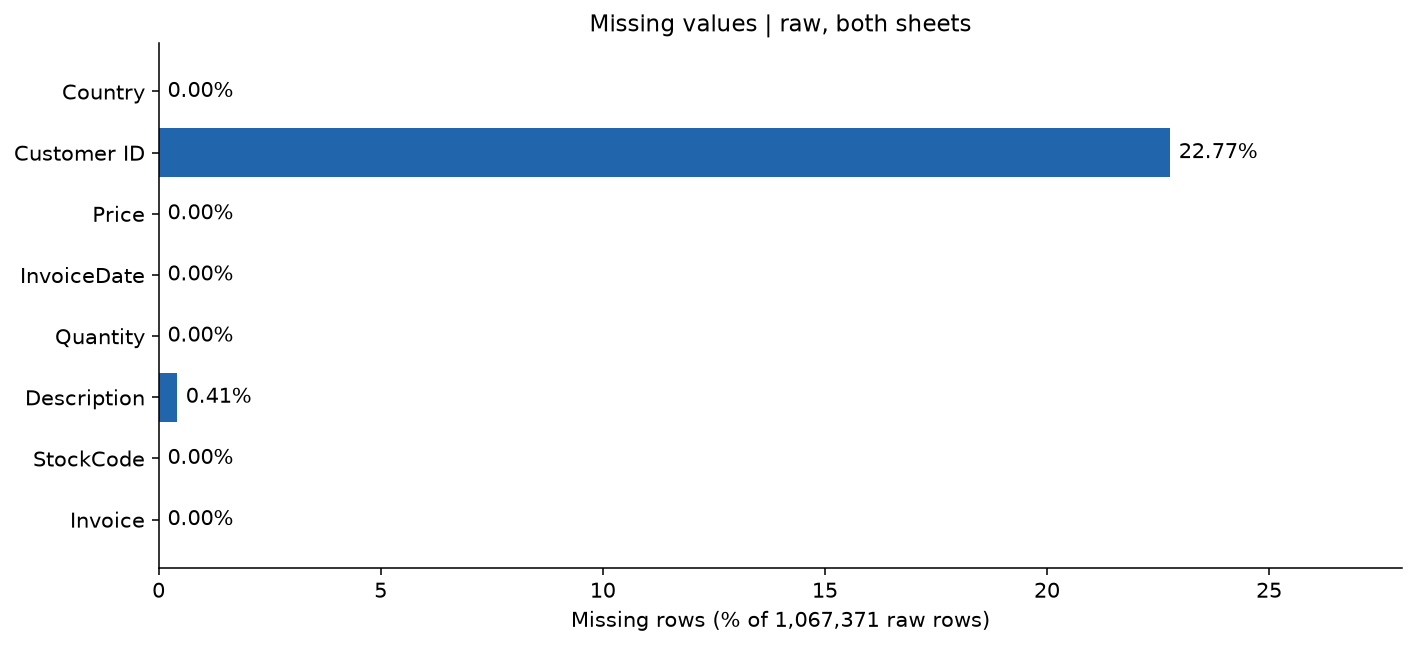

**Nhận xét:** Customer ID thiếu 243,007/1,067,371 dòng (22.77%); Description thiếu 4,382 dòng. Các cột còn lại không thiếu.

**Ý nghĩa đối với phân cụm:** Phân tích khách có ID chỉ đại diện phần định danh được; Guest không đại diện một cá nhân.

**Giới hạn / bước tiếp theo:** Không suy ra phân bố hành vi của dòng vô danh từ nhóm có ID; Description được pipeline điền nhưng không tạo thông tin sản phẩm mới.

In [4]:
show_figure(analysis, "missing_values_by_column")

### 2.1. Trùng, chứng từ đặc biệt và nhất quán

In [5]:
show_tables(analysis, ['duplicates', 'anomalies', 'consistency'])

**duplicates** — 5 dòng; đầy đủ ở `analysis['tables']['duplicates']`.

,definition,count,denominator_rows
0,Dòng trùng dư toàn bộ (keep=first),34335,1067371
1,Mọi dòng thuộc nhóm trùng (keep=False),67242,1067371
2,Tổng dòng trùng dư trong từng sheet,12133,1067371
3,Mẫu nội dung 8 cột chung giữa hai sheet,22202,1067371
4,Dòng sheet sau khớp mẫu sheet trước,22523,541910


**anomalies** — 7 dòng; đầy đủ ở `analysis['tables']['anomalies']`.

,condition,rows,denominator_rows,pct,invoices
0,Invoice có tiền tố C,19494,1067371,1.826357,8292
1,Quantity < 0,22950,1067371,2.150143,11684
2,Quantity = 0,0,1067371,0.000000,0
3,Price < 0,5,1067371,0.000468,5
4,Price = 0,6202,1067371,0.581054,5379
5,Quantity âm không C,3457,1067371,0.323880,3393
6,C có Quantity >= 0,1,1067371,0.000094,1


**consistency** — 4 dòng; đầy đủ ở `analysis['tables']['consistency']`.

,check,affected,denominator,pct
0,Invoice có nhiều Customer ID,0,53628,0.000000
1,Invoice có nhiều thời điểm,83,53628,0.154770
2,Khách có nhiều Country,13,5942,0.218782
3,StockCode có nhiều Description,1232,5304,23.227753


Bảng duplicates so đúng tám cột nguồn. keep=first đếm dòng dư;
keep=False đếm mọi dòng trong nhóm trùng; số mẫu chung khác số dòng sheet sau khớp.
Dòng dư toàn bộ = dòng dư trong từng sheet + mẫu chung. Trùng nội dung chưa xác minh là lỗi.
Bảng anomalies có nhóm giao nhau nên không cộng các tỷ lệ; C không là return_rate đã xác minh.
Invoice nhiều thời điểm ảnh hưởng R/gap; nhiều Country được giữ nhóm riêng ở cấp khách.


**Câu hỏi:** Chứng từ C chiếm bao nhiêu mã hóa đơn và dòng?

**Dữ liệu và phạm vi:** 1,067,371 dòng thô của hai sheet, giữ C, âm, trùng và ID thiếu.

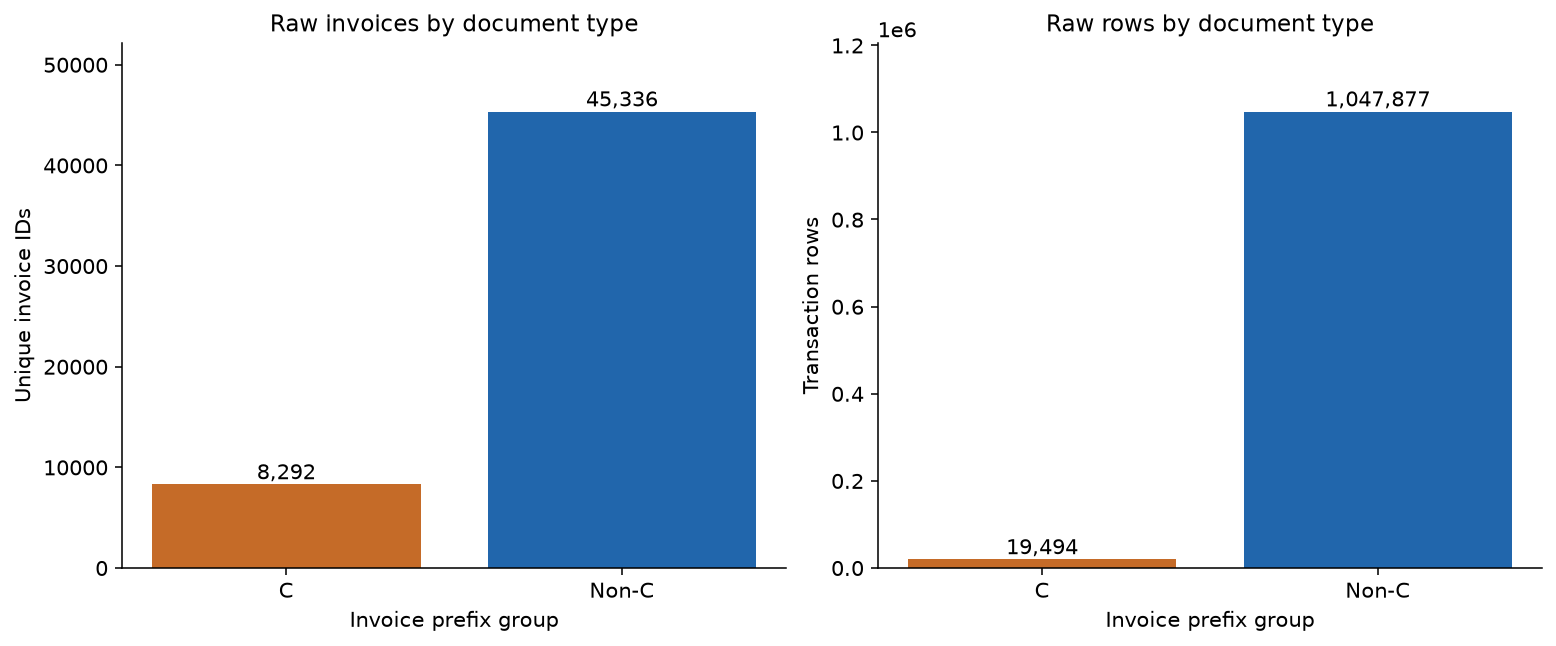

**Nhận xét:** Có 8,292/53,628 mã C (15.46%), tương ứng 19,494 dòng; mẫu số mã khác mẫu số dòng.

**Ý nghĩa đối với phân cụm:** Cần giữ chứng từ C để kiểm kê riêng trước khi tạo giá trị mua.

**Giới hạn / bước tiếp theo:** C là chỉ báo hủy theo UCI; chưa xác minh được trả hàng hay ghép đơn gốc. Không coi tỷ lệ mã C là return_rate.

In [6]:
show_figure(analysis, "invoices_by_c_prefix")

### 2.2. Kiểm kê mã hàng và phạm vi tiền xử lý

In [7]:
display(tables["stock_audit"].query("listed_special or not pattern_candidate")
        .sort_values("rows", ascending=False).head(15))


,rows,example_description,listed_special,pattern_candidate
StockCode,,,,
POST,2122,POSTAGE,True,False
DOT,1446,DOTCOM POSTAGE,True,False
M,1421,Manual,True,False
C2,282,CARRIAGE,True,False
D,177,Discount,True,False
S,104,SAMPLES,True,False
BANK CHARGES,102,Bank Charges | Bank Charges,True,False
ADJUST,67,Adjustment by john on 26/01/2010 16 | Adjustme...,True,False
AMAZONFEE,43,AMAZON FEE,True,False


Toàn bộ bảng kiểm kê mã có trong tables['stock_audit'].
SPECIAL_CODES là danh sách loại của pipeline, regex chỉ là hình thức mã; chưa có mapping sản phẩm.
Chính sách và đối chiếu từng bước với dữ liệu lịch sử được trình bày ở mục 10.


<a id="eda-distributions"></a>

## 3. Phân tích đơn biến

In [8]:
show_tables(analysis, ["customer_summary", "feature_missing"])

**customer_summary** — 1 dòng; đầy đủ ở `analysis['tables']['customer_summary']`.

,customers,invoices,rows,single_invoice_customers,multiple_timestamp_orders,multi_country_customers,exact_value_gbp,rounded_value_gbp
0,5849,36547,776238,1622,64,12,1.665034e+07,16650337.29


**feature_missing** — 5 dòng; đầy đủ ở `analysis['tables']['feature_missing']`.

,missing_customers
avg_purchase_gap_days,1622
n_distinct_products,5849
avg_quantity_per_order,5849
total_quantity,5849
return_rate,5849


In [9]:
columns = ["variable", "count", "missing", "mean", "median", "minimum", "maximum",
           "q1", "q3", "p95", "p99", "skewness"]
for name in ["transaction_profile", "customer_profile"]:
    display(Markdown(f"**{name}** — mô tả đơn biến; ngưỡng IQR xem mục 9."))
    display(tables[name][(["population"] if name == "transaction_profile" else []) + columns])


**transaction_profile** — mô tả đơn biến; ngưỡng IQR xem mục 9.

,population,variable,count,missing,mean,median,minimum,maximum,q1,q3,p95,p99,skewness
0,raw_including_C,Quantity,1067371,0,9.938898,3.00,-80995.000,80995.00,1.00,10.00,30.00,100.00,3.996145
1,raw_including_C,Price,1067371,0,4.649388,2.10,-53594.360,38970.00,1.25,4.15,9.95,18.00,-69.164734
2,raw_including_C,LineValue,1067371,0,18.069866,9.90,-168469.600,168469.60,3.75,17.70,59.50,180.00,-12.441961
3,current_pipeline_including_Guest,Quantity,1002995,0,10.619783,4.00,1.000,3500.00,1.00,12.00,32.00,106.00,30.445313
4,current_pipeline_including_Guest,Price,1002995,0,3.292919,2.10,0.001,59.57,1.25,4.13,9.95,16.95,3.400708
5,current_pipeline_including_Guest,LineValue,1002995,0,19.159846,10.08,0.001,8925.00,4.13,17.70,59.40,179.00,31.243576


**customer_profile** — mô tả đơn biến; ngưỡng IQR xem mục 9.

,variable,count,missing,mean,median,minimum,maximum,q1,q3,p95,p99,skewness
0,Recency,5849,0,200.394109,95.407639,0.465278,738.549306,25.467361,379.388889,623.457222,726.347889,0.892528
1,Frequency,5849,0,6.248419,3.000000,1.000000,373.000000,1.000000,7.000000,20.000000,46.000000,12.049266
2,Monetary,5849,0,2846.698121,851.880000,2.900000,580987.040000,335.520000,2232.490000,9035.554000,26295.099600,26.295066
3,avg_order_value,5849,0,359.661449,276.058571,2.900000,14844.766667,175.200000,409.268000,857.858261,1747.402560,12.770034
4,avg_purchase_gap_days,4227,1622,103.312251,72.893056,0.000000,714.152083,39.163472,130.947569,323.389583,487.195333,2.166458
5,observed_tenure_days,5849,0,473.989430,529.459722,0.488889,738.677083,311.494444,666.593750,735.497083,738.424667,-0.616355
6,n_stock_codes_candidate,5849,0,82.183279,45.000000,1.000000,2542.000000,19.000000,103.000000,281.000000,503.040000,6.218628
7,total_quantity_candidate,5849,0,1703.247564,484.000000,1.000000,367066.000000,189.000000,1351.000000,5342.400000,16383.320000,24.687180
8,avg_quantity_per_order_candidate,5849,0,227.748926,155.000000,1.000000,37847.000000,92.166667,259.750000,549.978022,1274.080000,42.549649


**Câu hỏi:** Quantity, Price, LineValue lệch và có đuôi thế nào?

**Dữ liệu và phạm vi:** 1,067,371 dòng thô của hai sheet, giữ C, âm, trùng và ID thiếu.

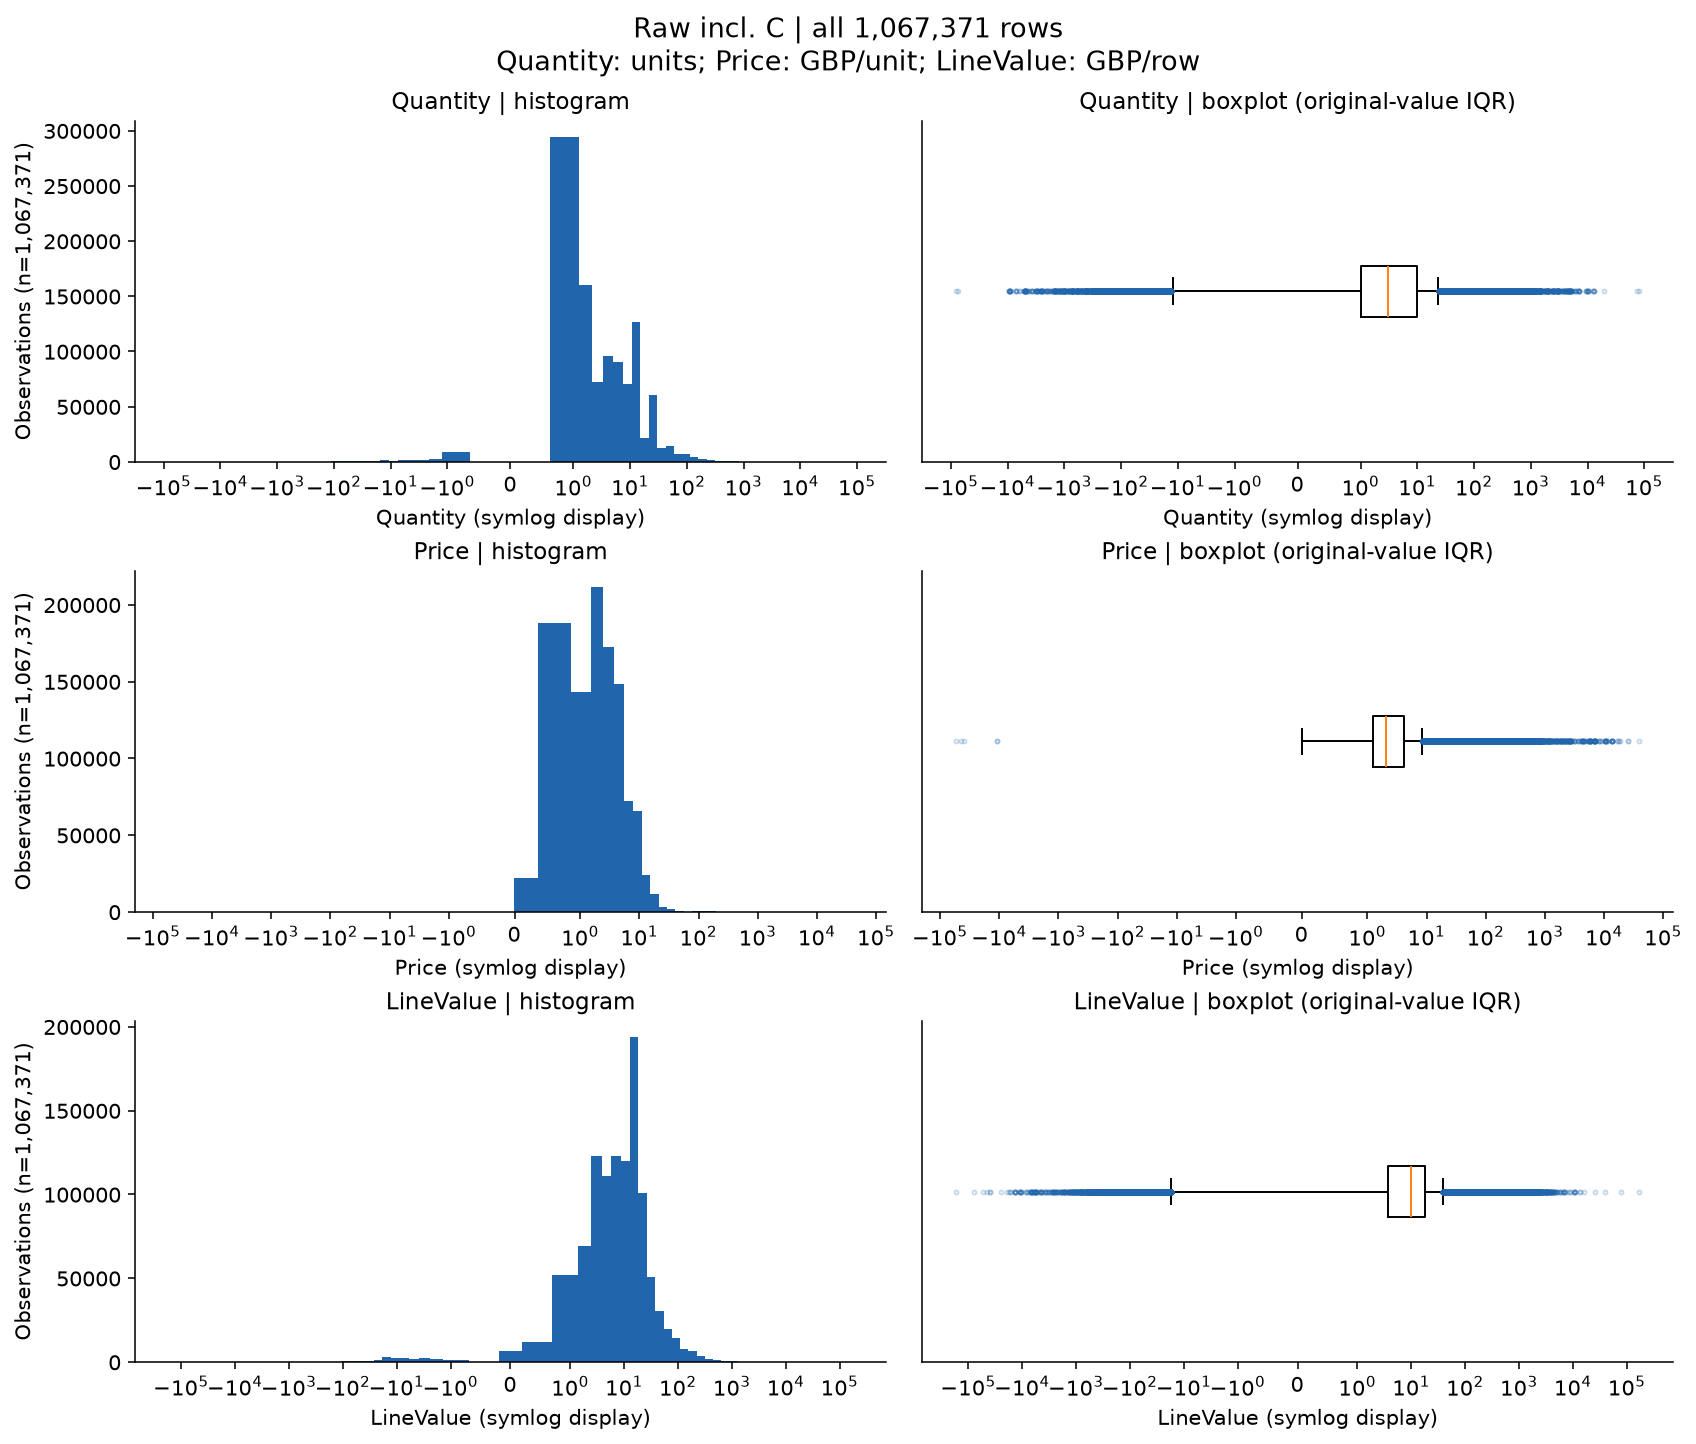

**Nhận xét:** Quantity: median=3.00, P99=100.00, min=-80,995.00, max=80,995.00, skew=4.00; Price: median=2.10, P99=18.00, min=-53,594.36, max=38,970.00, skew=-69.16; LineValue: median=9.90, P99=180.00, min=-168,469.60, max=168,469.60, skew=-12.44.

**Ý nghĩa đối với phân cụm:** Miền âm/dương và cực trị khiến mean đơn lẻ khó diễn giải; cần chọn góc nhìn mua trước log/scaling.

**Giới hạn / bước tiếp theo:** Histogram có bin symlog; boxplot giữ toàn miền symlog, ngưỡng IQR tính trên thang gốc. Skew có dấu của giá/giá trị thô chịu tác động cực trị âm; không tự gọi mọi biến là lệch phải. Không cắt dữ liệu.

In [10]:
show_figure(analysis, "raw_transaction_full_distributions")

**Câu hỏi:** Sau các bộ lọc hiện tại, đuôi phân phối còn lớn không?

**Dữ liệu và phạm vi:** 1,002,995 dòng đầu ra clean_data, gồm Guest; Q/P dương, đã lọc log-IQR k=3 của pipeline.

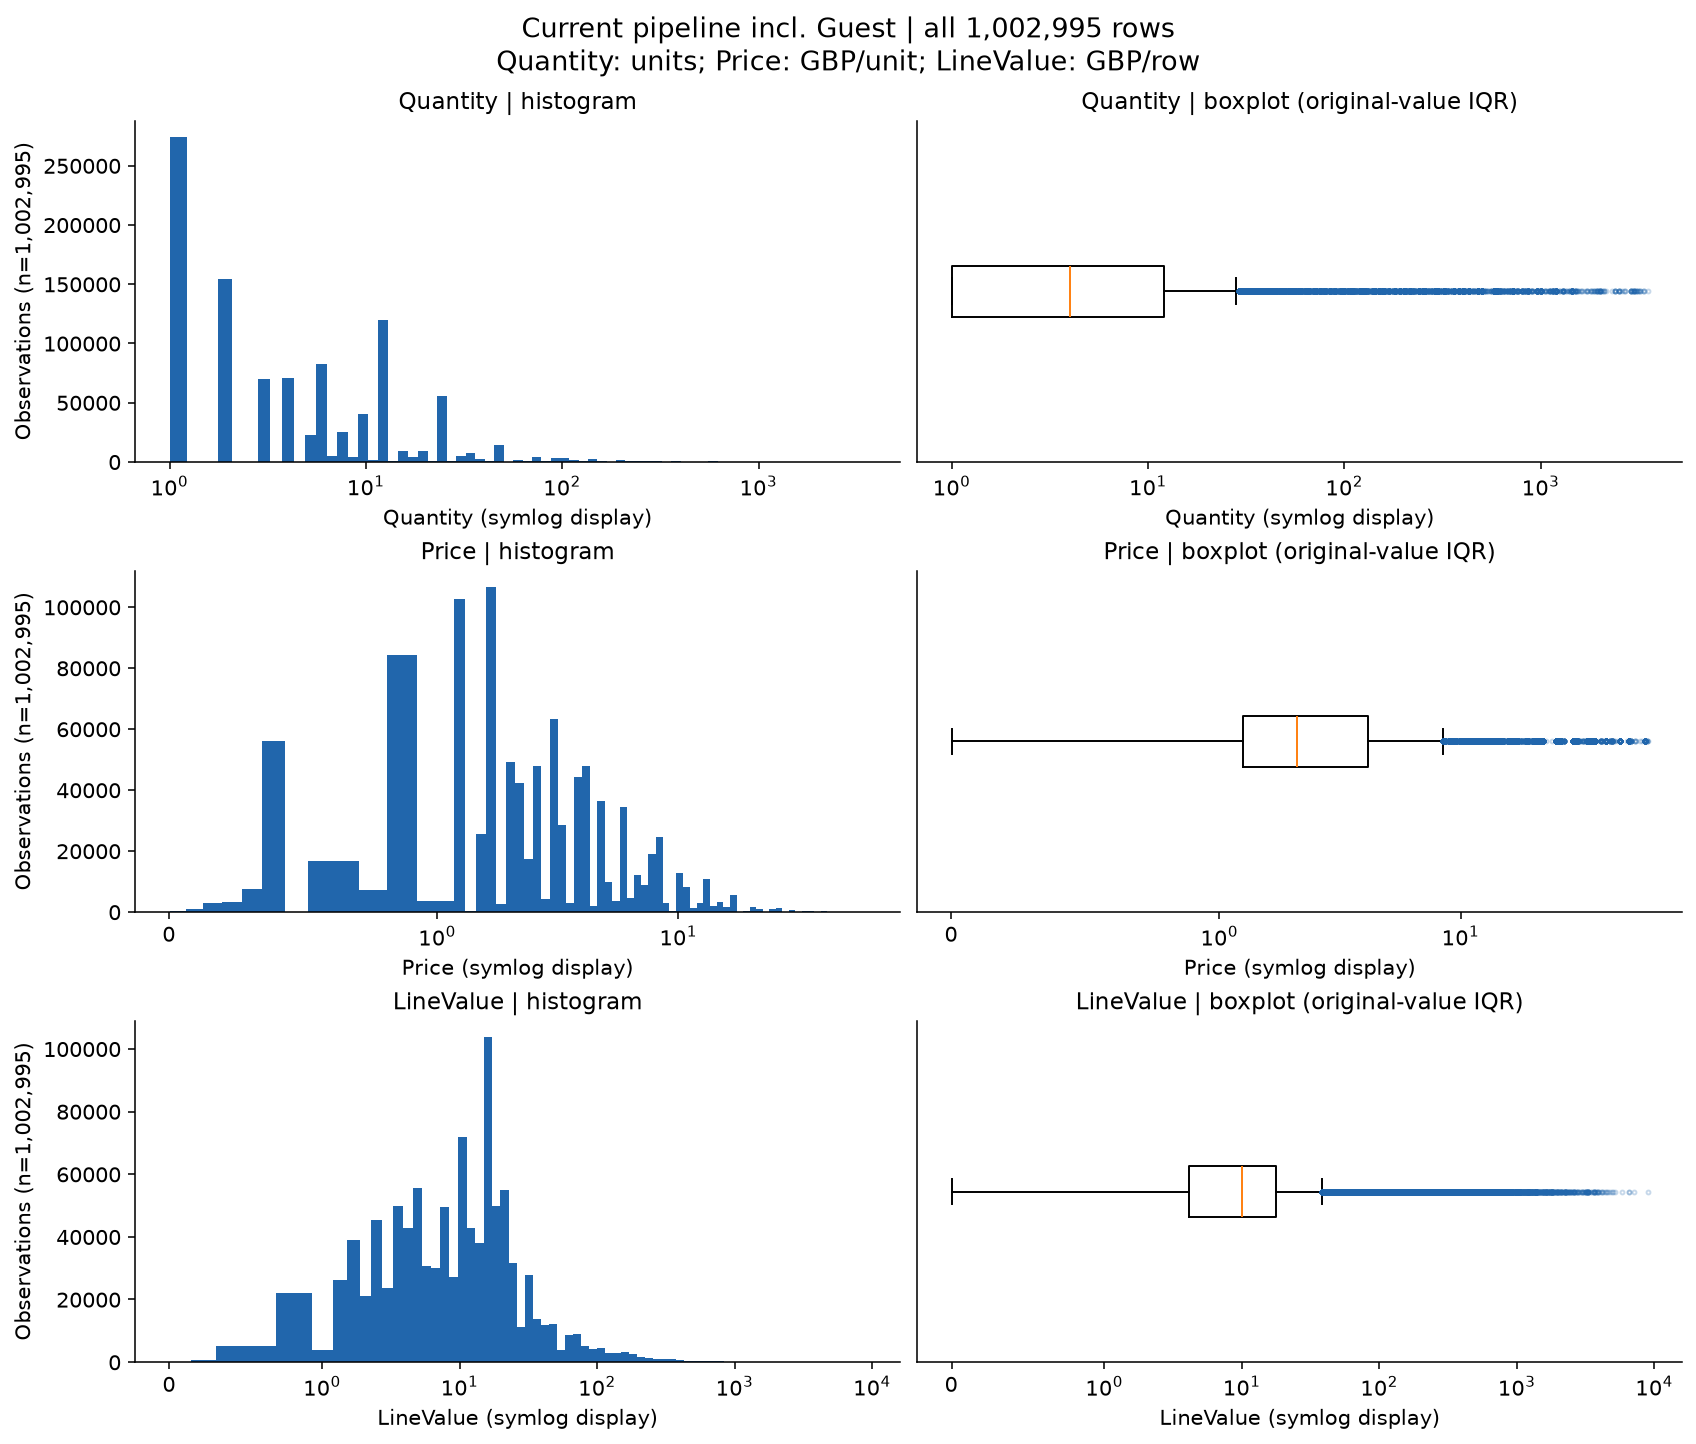

**Nhận xét:** Quantity: median=4.00, P99=106.00, max=3,500.00, ngoài IQR1.5=52,955; Price: median=2.10, P99=16.95, max=59.57, ngoài IQR1.5=74,757; LineValue: median=10.08, P99=179.00, max=8,925.00, ngoài IQR1.5=81,705.

**Ý nghĩa đối với phân cụm:** Lọc cực trị ở cấp dòng của pipeline chưa làm mất toàn bộ đuôi dài ở cấp khách; cần kiểm tra độ nhạy khi phân cụm.

**Giới hạn / bước tiếp theo:** EDA chỉ gắn cờ IQR1.5 trên thang gốc, không xóa thêm dòng/khách. Pipeline đã loại log-IQR k=3 là chính sách hiện có của Thuận; đề xuất giữ/xử lý khác cần nhóm xác nhận.

In [11]:
show_figure(analysis, "clean_transaction_full_distributions")

Hai hình trên đối chiếu thô và đầu ra pipeline theo đúng phạm vi ghi dưới hình.
[Ngưỡng IQR và ví dụ cực trị](#eda-outliers) ở mục 9 bổ sung bằng chứng điều tra;
không vẽ lại các phân phối hoặc tự xóa thêm khách giá trị cao.


**Câu hỏi:** Các nhóm StockCode tập trung ở đâu?

**Dữ liệu và phạm vi:** 1,067,371 dòng thô của hai sheet, giữ C, âm, trùng và ID thiếu.

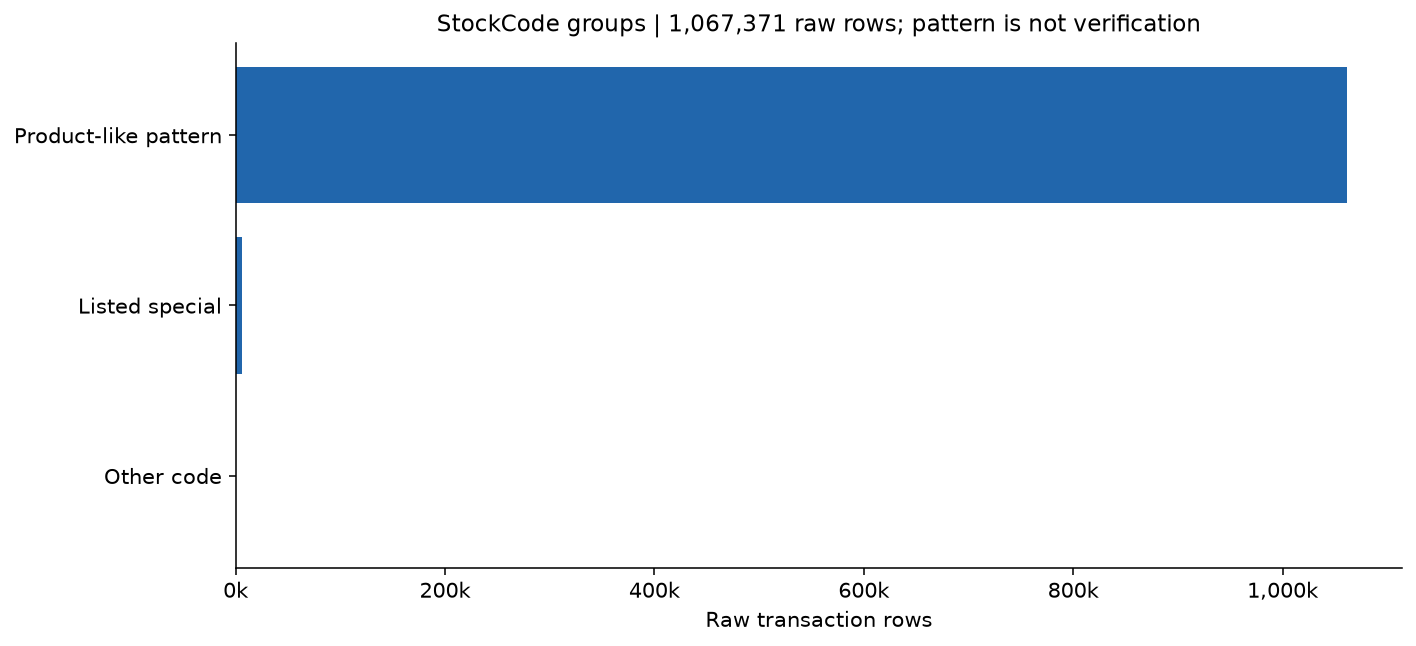

**Nhận xét:** Product-like pattern: 1,061,278 dòng (99.43%); Listed special: 5,812 dòng (0.54%); Other code: 281 dòng (0.03%). Nhãn nhóm mã chỉ dựa danh sách pipeline và hình thức mã.

**Ý nghĩa đối với phân cụm:** Không đồng nhất số StockCode ứng viên với số sản phẩm đã xác minh.

**Giới hạn / bước tiếp theo:** SPECIAL_CODES chỉ là danh sách loại hiện tại; regex không xác nhận sản phẩm. Mỗi dòng thuộc đúng một nhóm trong hình.

In [12]:
show_figure(analysis, "raw_categorical_distributions")

**Câu hỏi:** Hành vi từng khách có phân phối lệch đến đâu?

**Dữ liệu và phạm vi:** Thử nghiệm trên 5,849 khách có ID; một dòng/khách, sau clean_data hiện tại; cửa sổ [2009-12-01, 2011-12-10). Guest được loại khỏi khảo sát khách sau pipeline.

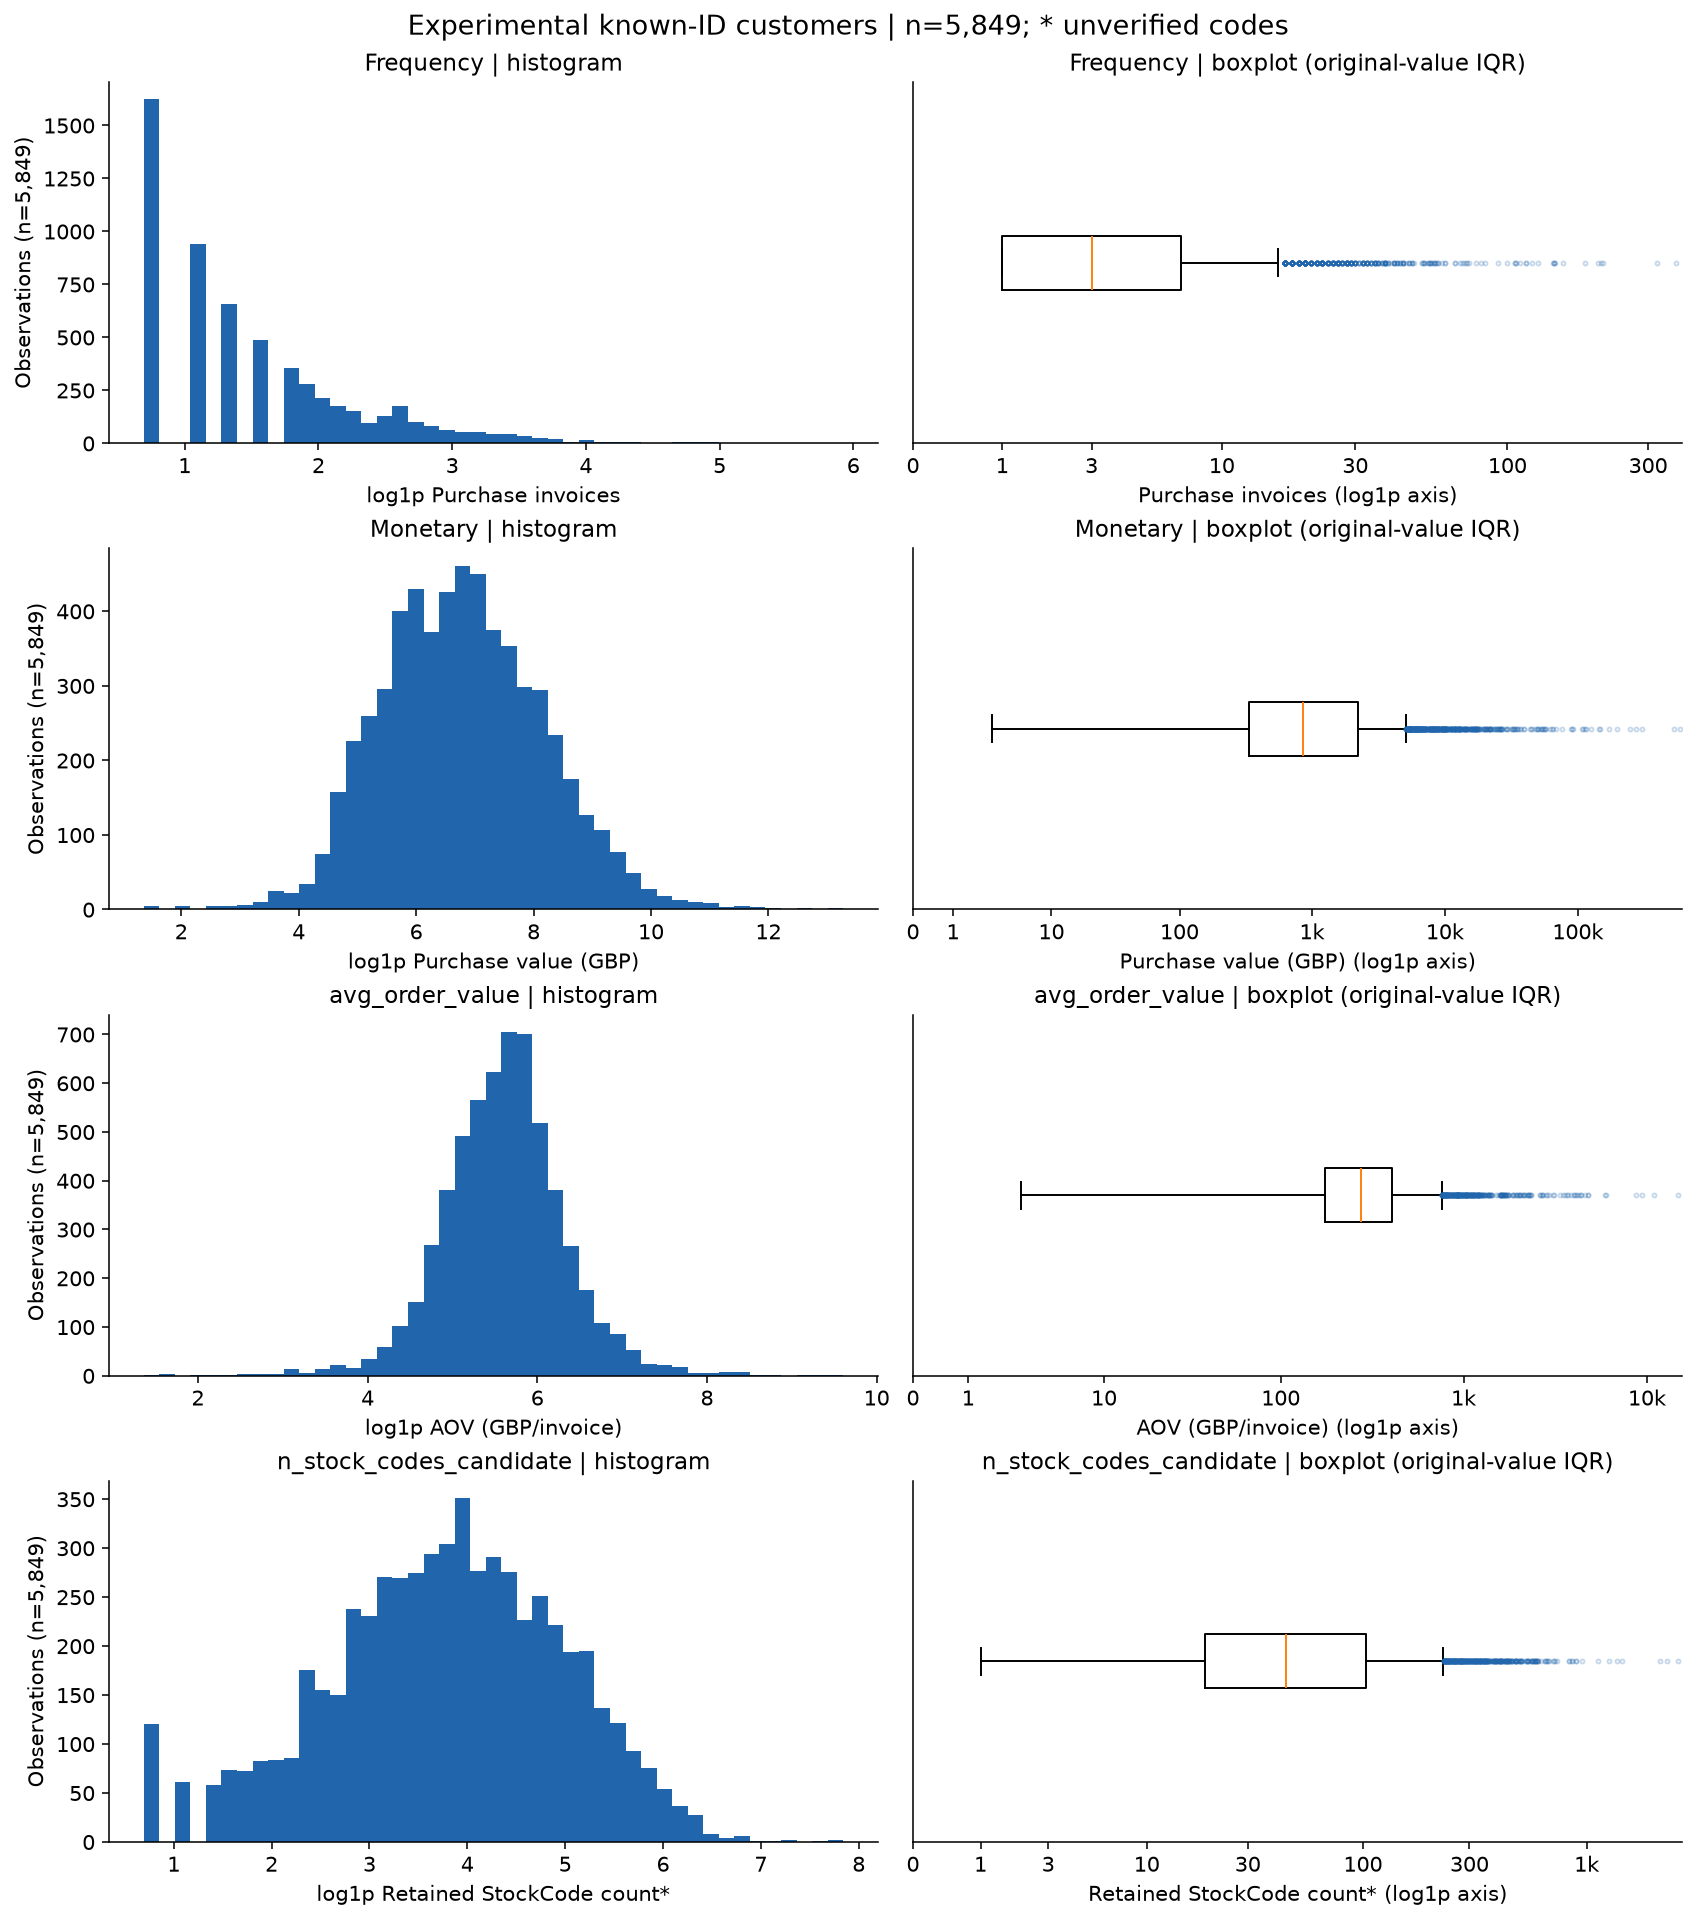

**Nhận xét:** Purchase invoices: median=3.00, P99=46.00, max=373.00, skew=12.05; Purchase value (GBP): median=851.88, P99=26,295.10, max=580,987.04, skew=26.30; AOV (GBP/invoice): median=276.06, P99=1,747.40, max=14,844.77, skew=12.77; Retained StockCode count*: median=45.00, P99=503.04, max=2,542.00, skew=6.22.

**Ý nghĩa đối với phân cụm:** Đuôi dài có thể chi phối khoảng cách Euclidean; khảo sát log1p/scaling và độ nhạy thay vì loại khách giá trị lớn.

**Giới hạn / bước tiếp theo:** Histogram và boxplot dùng thang log1p hiển thị, không xóa khách. * chỉ mã/đơn vị ứng viên; chưa xác minh danh mục sản phẩm.

In [13]:
show_figure(analysis, "customer_behavior_distributions")

**Câu hỏi:** Có bao nhiêu khách đủ lịch sử để tính khoảng cách mua?

**Dữ liệu và phạm vi:** Thử nghiệm trên 5,849 khách có ID; một dòng/khách, sau clean_data hiện tại; cửa sổ [2009-12-01, 2011-12-10). Guest được loại khỏi khảo sát khách sau pipeline.

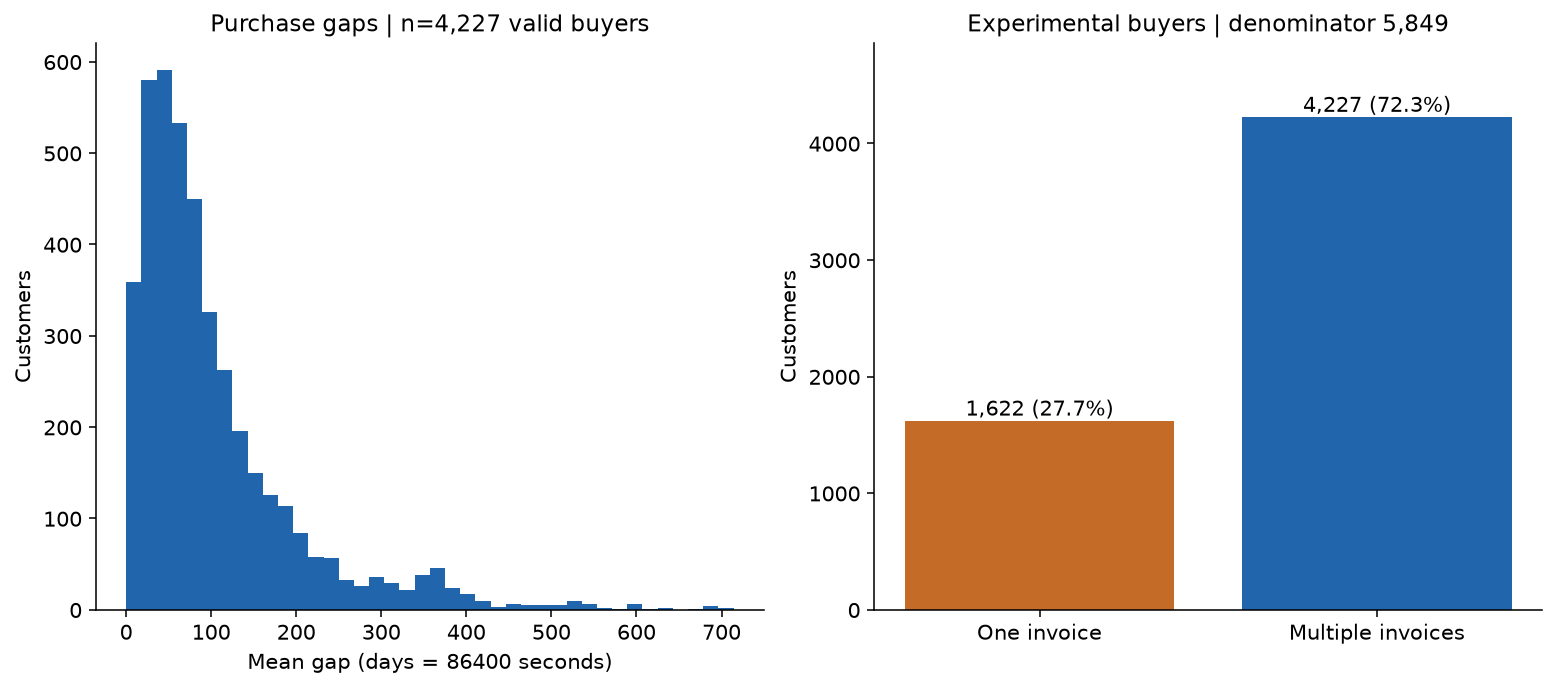

**Nhận xét:** 1,622/5,849 khách (27.73%) chỉ một Invoice; 4,227 khách còn lại có gap, trung vị 72.89 ngày. Gap nhỏ nhất 0.00 ngày.

**Ý nghĩa đối với phân cụm:** Gap thiếu có ý nghĩa cấu trúc; khi phân cụm cần chính sách thiếu/cờ một đơn, giữ 0 thật nếu các hóa đơn cùng thời điểm.

**Giới hạn / bước tiếp theo:** Không điền NaN bằng 0. Invoice nhiều thời điểm dùng earliest trong các dòng giữ lại; chưa biết lịch sử trước/sau cửa sổ.

In [14]:
show_figure(analysis, "customer_purchase_gaps")

## 4. Phân tích theo thời gian

In [15]:
show_tables(analysis, ['monthly', 'weekday', 'hour'])

**monthly** — 25 dòng; đầy đủ ở `analysis['tables']['monthly']`.

,rows,invoices,signed_value_gbp,current_value_gbp,partial_boundary
month,,,,,
2009-12,45228,2330,799847.110,792678.220,False
2010-01,31555,1633,624032.892,605512.672,False
2010-02,29388,1969,533091.426,525731.216,False
2010-03,41511,2367,765848.761,742511.141,False
2010-04,34057,1892,590580.432,645021.522,False
2010-05,35323,2418,615322.830,636205.940,False
2010-06,39983,2216,679786.610,694965.100,False
2010-07,33383,2017,575236.360,628008.070,False
2010-08,33306,1877,656776.340,664658.850,False


**weekday** — 7 dòng; đầy đủ ở `analysis['tables']['weekday']`.

,rows
InvoiceDate,
0,189084
1,196626
2,185051
3,203149
4,153803
5,402
6,139256


**hour** — 24 dòng; đầy đủ ở `analysis['tables']['hour']`.

,rows
InvoiceDate,
0,0
1,0
2,0
3,0
4,0
5,0
6,41
7,1127
8,15985


**Câu hỏi:** Số Invoice duy nhất biến động theo tháng ra sao?

**Dữ liệu và phạm vi:** 1,067,371 dòng thô của hai sheet, giữ C, âm, trùng và ID thiếu.

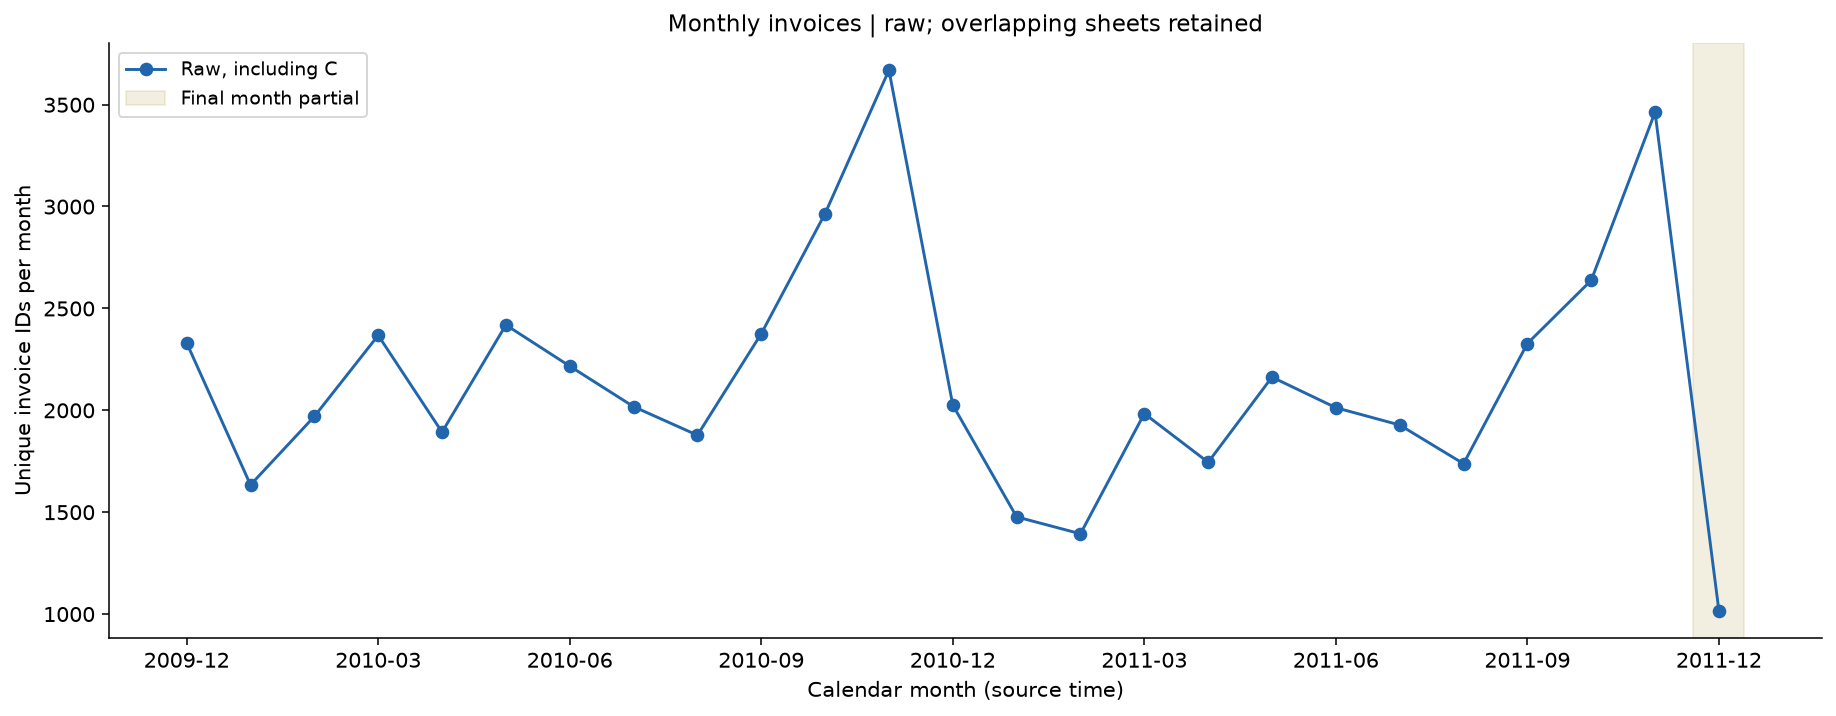

**Nhận xét:** Có 25 tháng; tháng nhiều mã chứng từ nhất 2010-11: 3,669. Tháng cuối 2011-12 có 1,015 mã và 25,526 dòng, chỉ đến 09/12/2011.

**Ý nghĩa đối với phân cụm:** Mức hoạt động và độ dài quan sát có thể ảnh hưởng Frequency/tenure.

**Giới hạn / bước tiếp theo:** Bao gồm C. Tháng 12/2010 có hai sheet chồng lấn và có dòng trùng; 12/2011 chưa đủ tháng. Không suy diễn mùa vụ dài hạn hay nguyên nhân từ đường xu hướng.

In [16]:
show_figure(analysis, "invoices_by_month")

**Câu hỏi:** Giá trị có dấu và giá trị giữ lại bởi pipeline khác nhau thế nào?

**Dữ liệu và phạm vi:** 1,067,371 dòng thô của hai sheet, giữ C, âm, trùng và ID thiếu. Đường thứ hai: 1,002,995 dòng sau clean_data, gồm Guest.

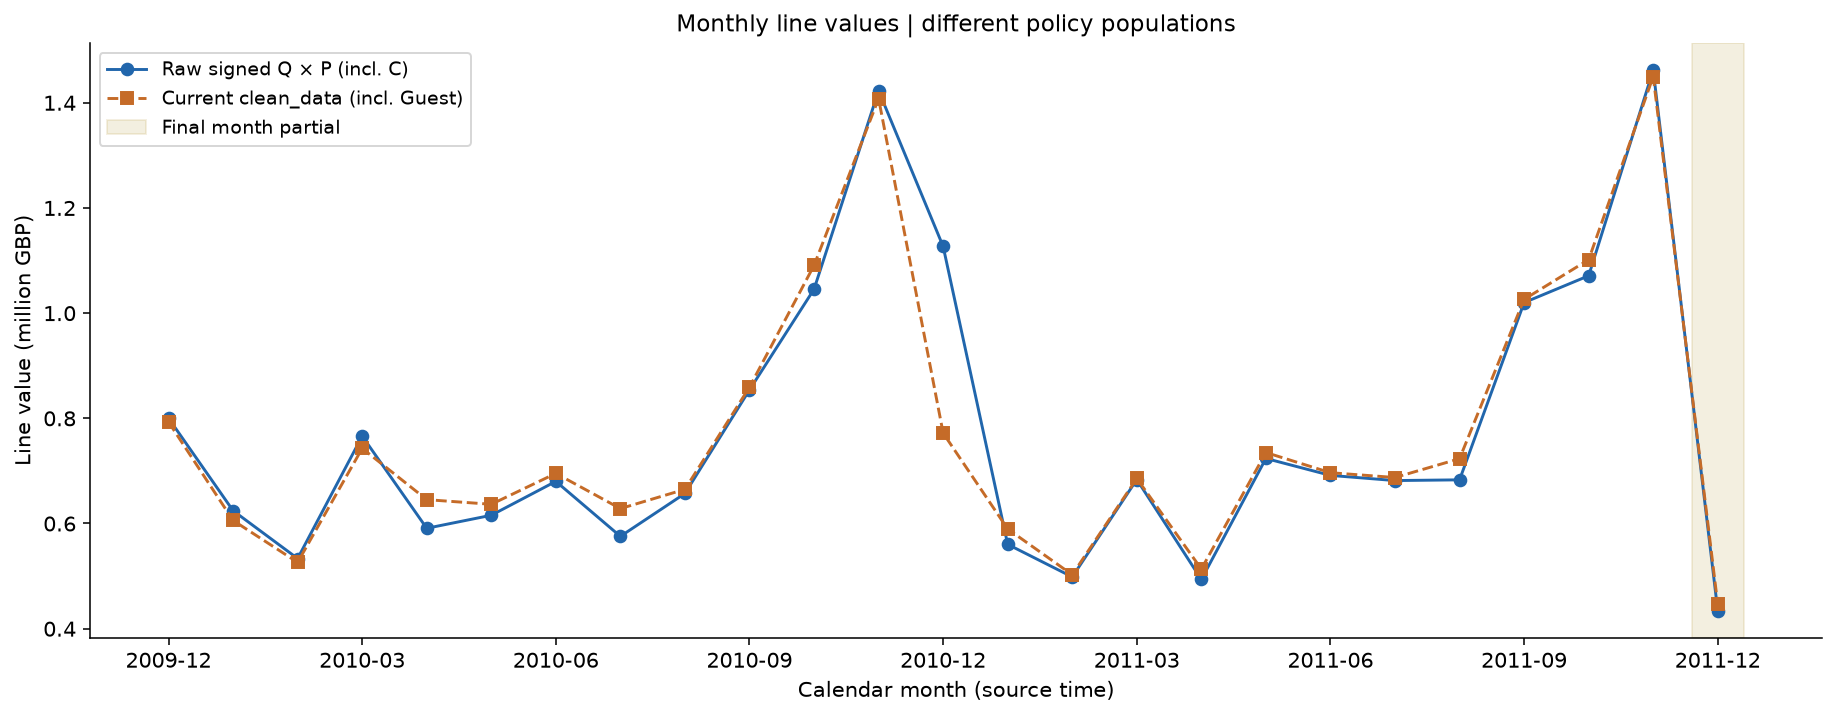

**Nhận xét:** Tổng thô có dấu 19,287,250.568 GBP; sau pipeline 19,217,229.717 GBP. Tháng cuối tương ứng 433,686.01 và 446,029.65 GBP.

**Ý nghĩa đối với phân cụm:** Phải giữ nhãn phạm vi khi diễn giải Monetary; loại C/âm và ngoại lệ thay đổi giá trị được quan sát.

**Giới hạn / bước tiếp theo:** Hai đường khác quần thể/chính sách, không phải tác động nhân quả hoặc doanh thu thuần đã xác minh. Giá trị dùng Q×P chính xác, không cộng Revenue đã làm tròn.

In [17]:
show_figure(analysis, "signed_line_value_by_month")

**Câu hỏi:** Dòng giao dịch tập trung vào thứ và giờ nào?

**Dữ liệu và phạm vi:** 1,067,371 dòng thô của hai sheet, giữ C, âm, trùng và ID thiếu.

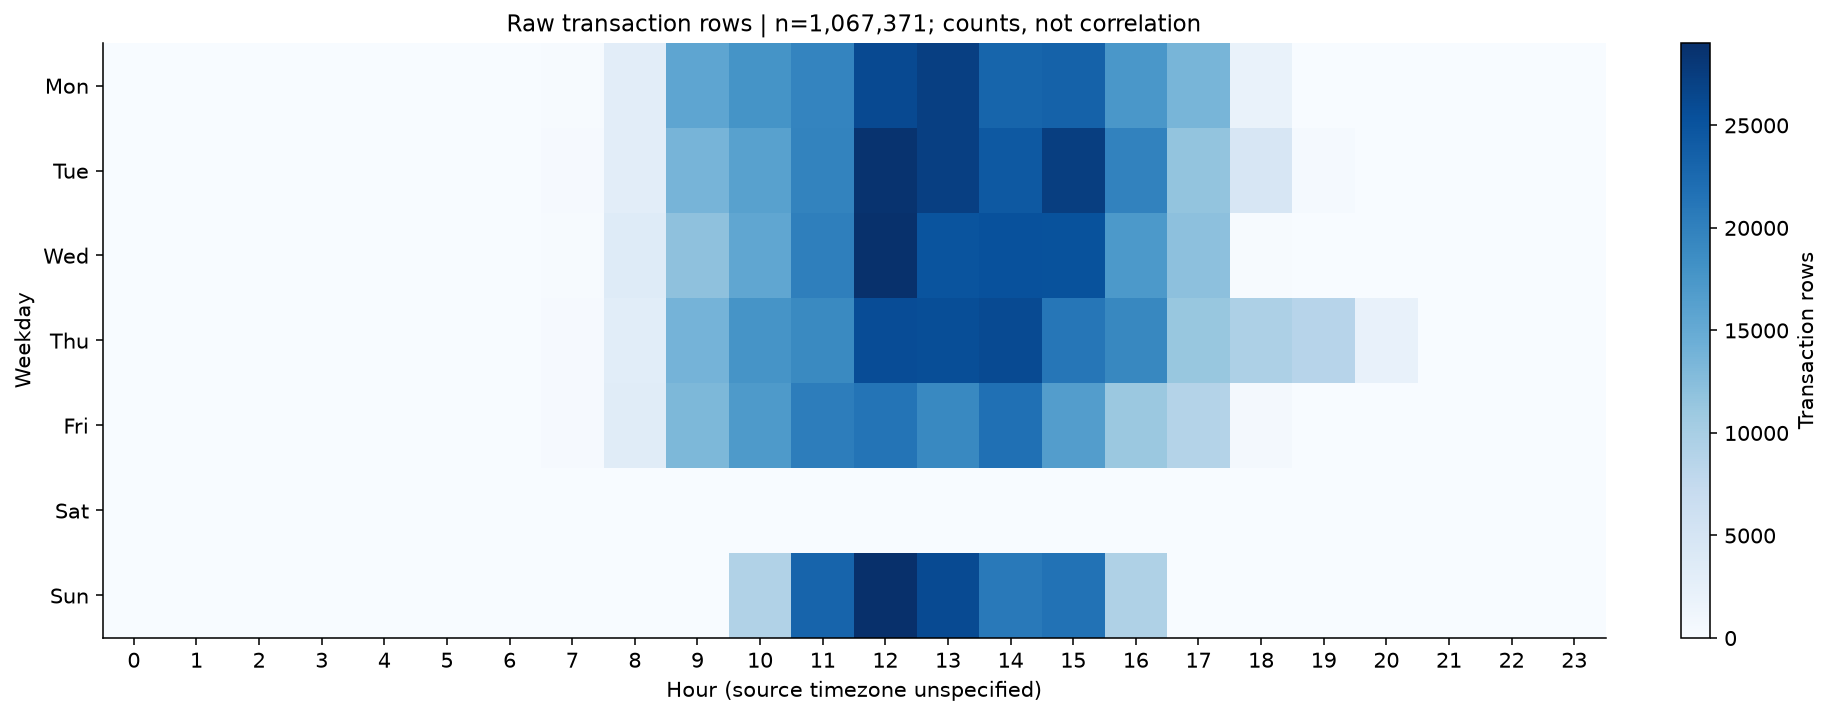

**Nhận xét:** Ô cao nhất là Sunday lúc 12 giờ: 29,003 dòng; tổng các ô 1,067,371 dòng.

**Ý nghĩa đối với phân cụm:** Giúp mô tả thời điểm hoạt động, chưa đủ căn cứ chọn đặc trưng thói quen từng khách.

**Giới hạn / bước tiếp theo:** Đây là heatmap tần suất, không phải tương quan. Giờ nguồn không có múi giờ; không tự chuyển sang giờ Bangkok. Ô không xuất hiện được biểu diễn bằng 0 đếm.

In [18]:
show_figure(analysis, "transactions_by_weekday_hour")

## 5. Phân tích theo quốc gia

In [19]:
show_tables(analysis, ['countries'])

**countries** — 43 dòng; đầy đủ ở `analysis['tables']['countries']`.

,rows,invoices,customers,signed_value_gbp
Country,,,,
United Kingdom,981330,49108,5410,1.638258e+07
EIRE,17866,806,5,6.155196e+05
Germany,17624,1095,107,4.179886e+05
France,14330,746,95,3.281918e+05
Netherlands,5140,250,23,5.485249e+05
Spain,3811,188,41,9.185948e+04
Switzerland,3189,123,22,9.972876e+04
Belgium,3123,183,29,6.357449e+04
Portugal,2620,124,24,5.313680e+04


**Câu hỏi:** Quốc gia nào chiếm ưu thế theo bốn đơn vị đo?

**Dữ liệu và phạm vi:** 1,067,371 dòng thô của hai sheet, giữ C, âm, trùng và ID thiếu. Top 10 theo số dòng; bảng đầy đủ giữ trong tables['countries'].

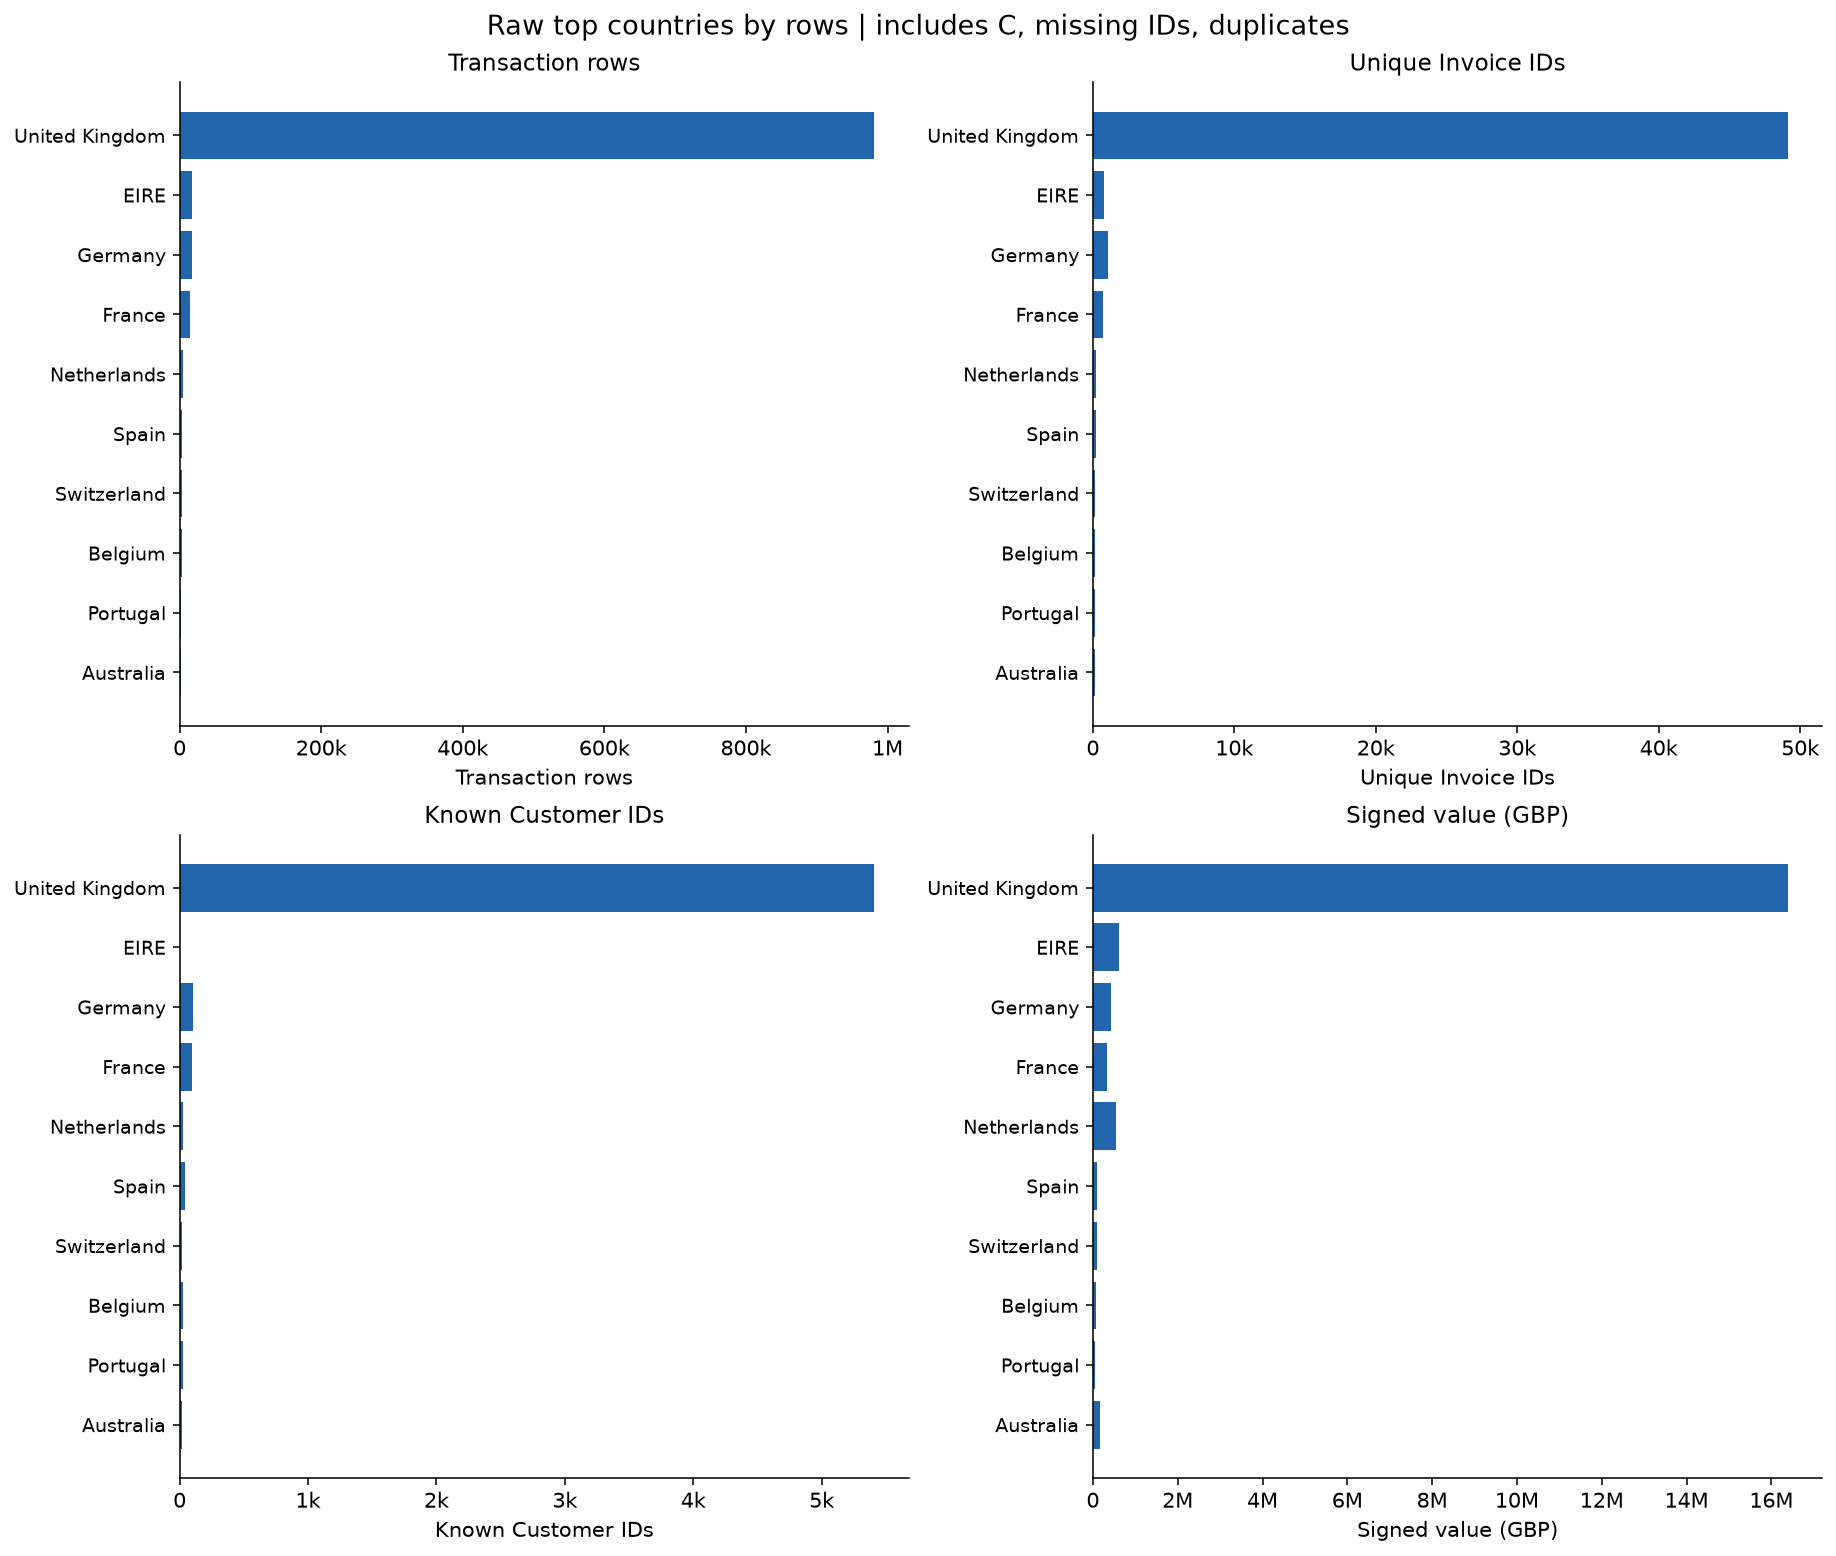

**Nhận xét:** UK: 981,330/1,067,371 dòng (91.94%), 49,108 mã Invoice, 5,410 khách và giá trị có dấu 16,382,583.90 GBP. Ngoài UK, EIRE dẫn đầu số dòng (17,866).

**Ý nghĩa đối với phân cụm:** Cụm toàn bộ dữ liệu sẽ phản ánh mạnh thị trường UK; nên kiểm tra hồ sơ cụm theo quốc gia.

**Giới hạn / bước tiếp theo:** Khách hoặc Invoice có thể thuộc nhiều quốc gia nên số đếm distinct theo quốc gia không cộng thành tổng toàn nguồn. Unspecified là nhãn chưa xác định; hình ngoài UK không đại diện cơ cấu toàn bộ.

In [20]:
show_figure(analysis, "country_activity")

**Câu hỏi:** Ngoài UK, thị trường nào nổi bật?

**Dữ liệu và phạm vi:** 1,067,371 dòng thô của hai sheet, giữ C, âm, trùng và ID thiếu. Top 10 theo số dòng; bảng đầy đủ giữ trong tables['countries'].

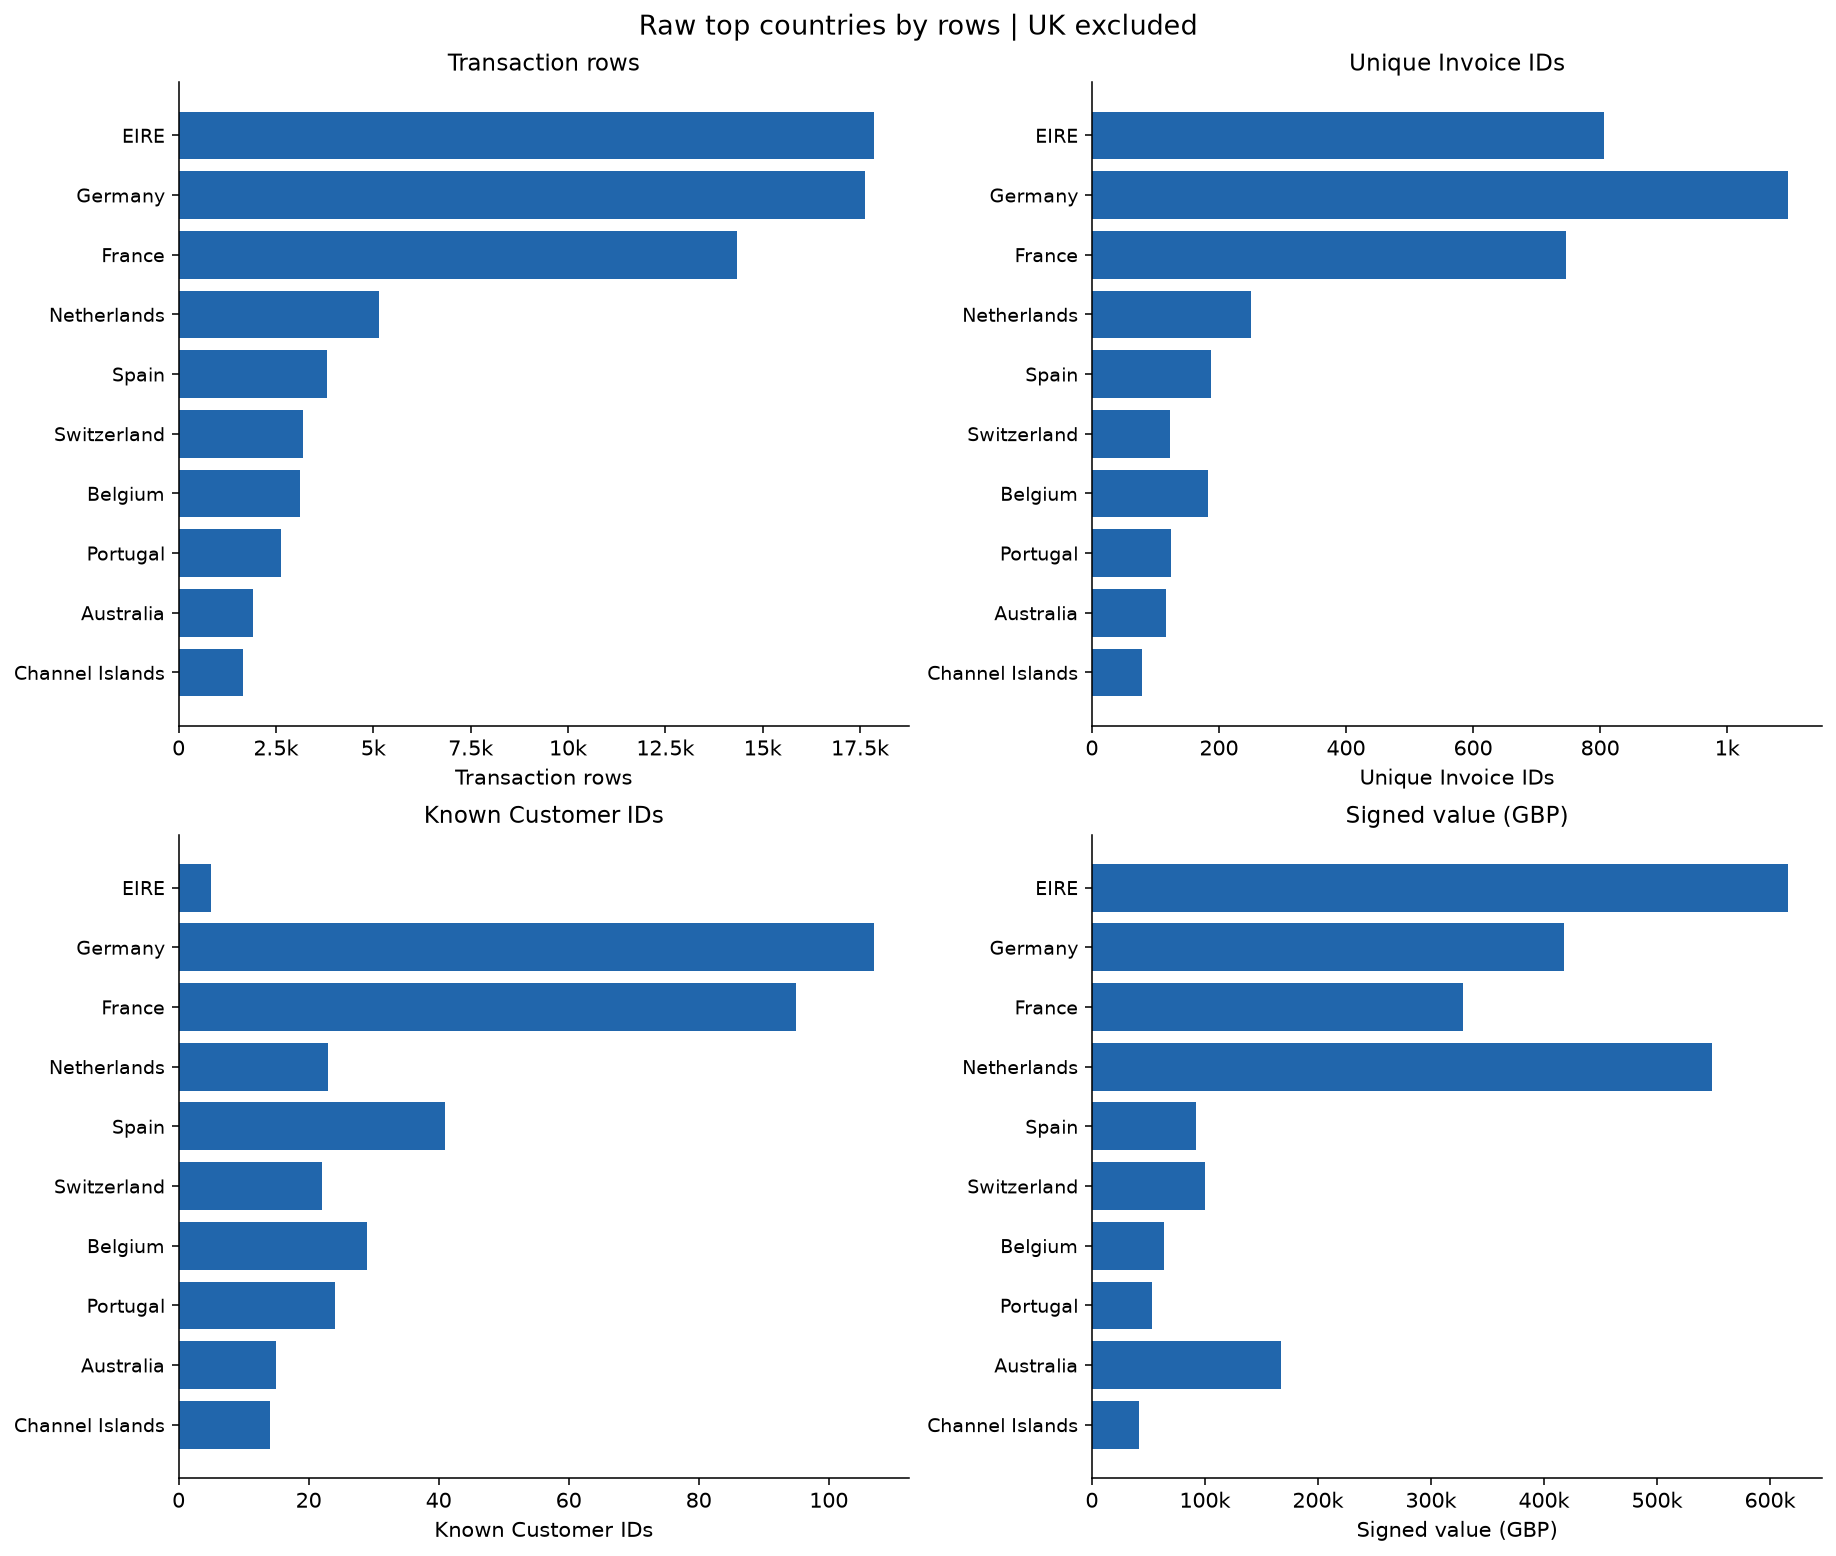

**Nhận xét:** UK: 981,330/1,067,371 dòng (91.94%), 49,108 mã Invoice, 5,410 khách và giá trị có dấu 16,382,583.90 GBP. Ngoài UK, EIRE dẫn đầu số dòng (17,866).

**Ý nghĩa đối với phân cụm:** Cụm toàn bộ dữ liệu sẽ phản ánh mạnh thị trường UK; nên kiểm tra hồ sơ cụm theo quốc gia.

**Giới hạn / bước tiếp theo:** Khách hoặc Invoice có thể thuộc nhiều quốc gia nên số đếm distinct theo quốc gia không cộng thành tổng toàn nguồn. Unspecified là nhãn chưa xác định; hình ngoài UK không đại diện cơ cấu toàn bộ.

In [21]:
show_figure(analysis, "country_activity_excluding_uk")

<a id="eda-relationships"></a>

## 6. Phân tích hai biến

### 6.1. Num vs Num

In [22]:
show_tables(analysis, ['bivariate_numeric'])

**bivariate_numeric** — 6 dòng; đầy đủ ở `analysis['tables']['bivariate_numeric']`.

,x,y,spearman,pearson,n
0,Frequency,Monetary,0.860283,0.629362,5849
1,Recency,Monetary,-0.509819,-0.124917,5849
2,Frequency,avg_order_value,0.212846,0.102903,5849
3,n_stock_codes_candidate,Monetary,0.776023,0.410606,5849
4,total_quantity_candidate,Monetary,0.948603,0.929404,5849
5,avg_quantity_per_order_candidate,avg_order_value,0.827242,0.585618,5849


**Câu hỏi:** F–M, R–M, F–AOV, số mã–M và lượng–giá trị liên hệ thế nào?

**Dữ liệu và phạm vi:** Thử nghiệm trên 5,849 khách có ID; một dòng/khách, sau clean_data hiện tại; cửa sổ [2009-12-01, 2011-12-10). Guest được loại khỏi khảo sát khách sau pipeline.

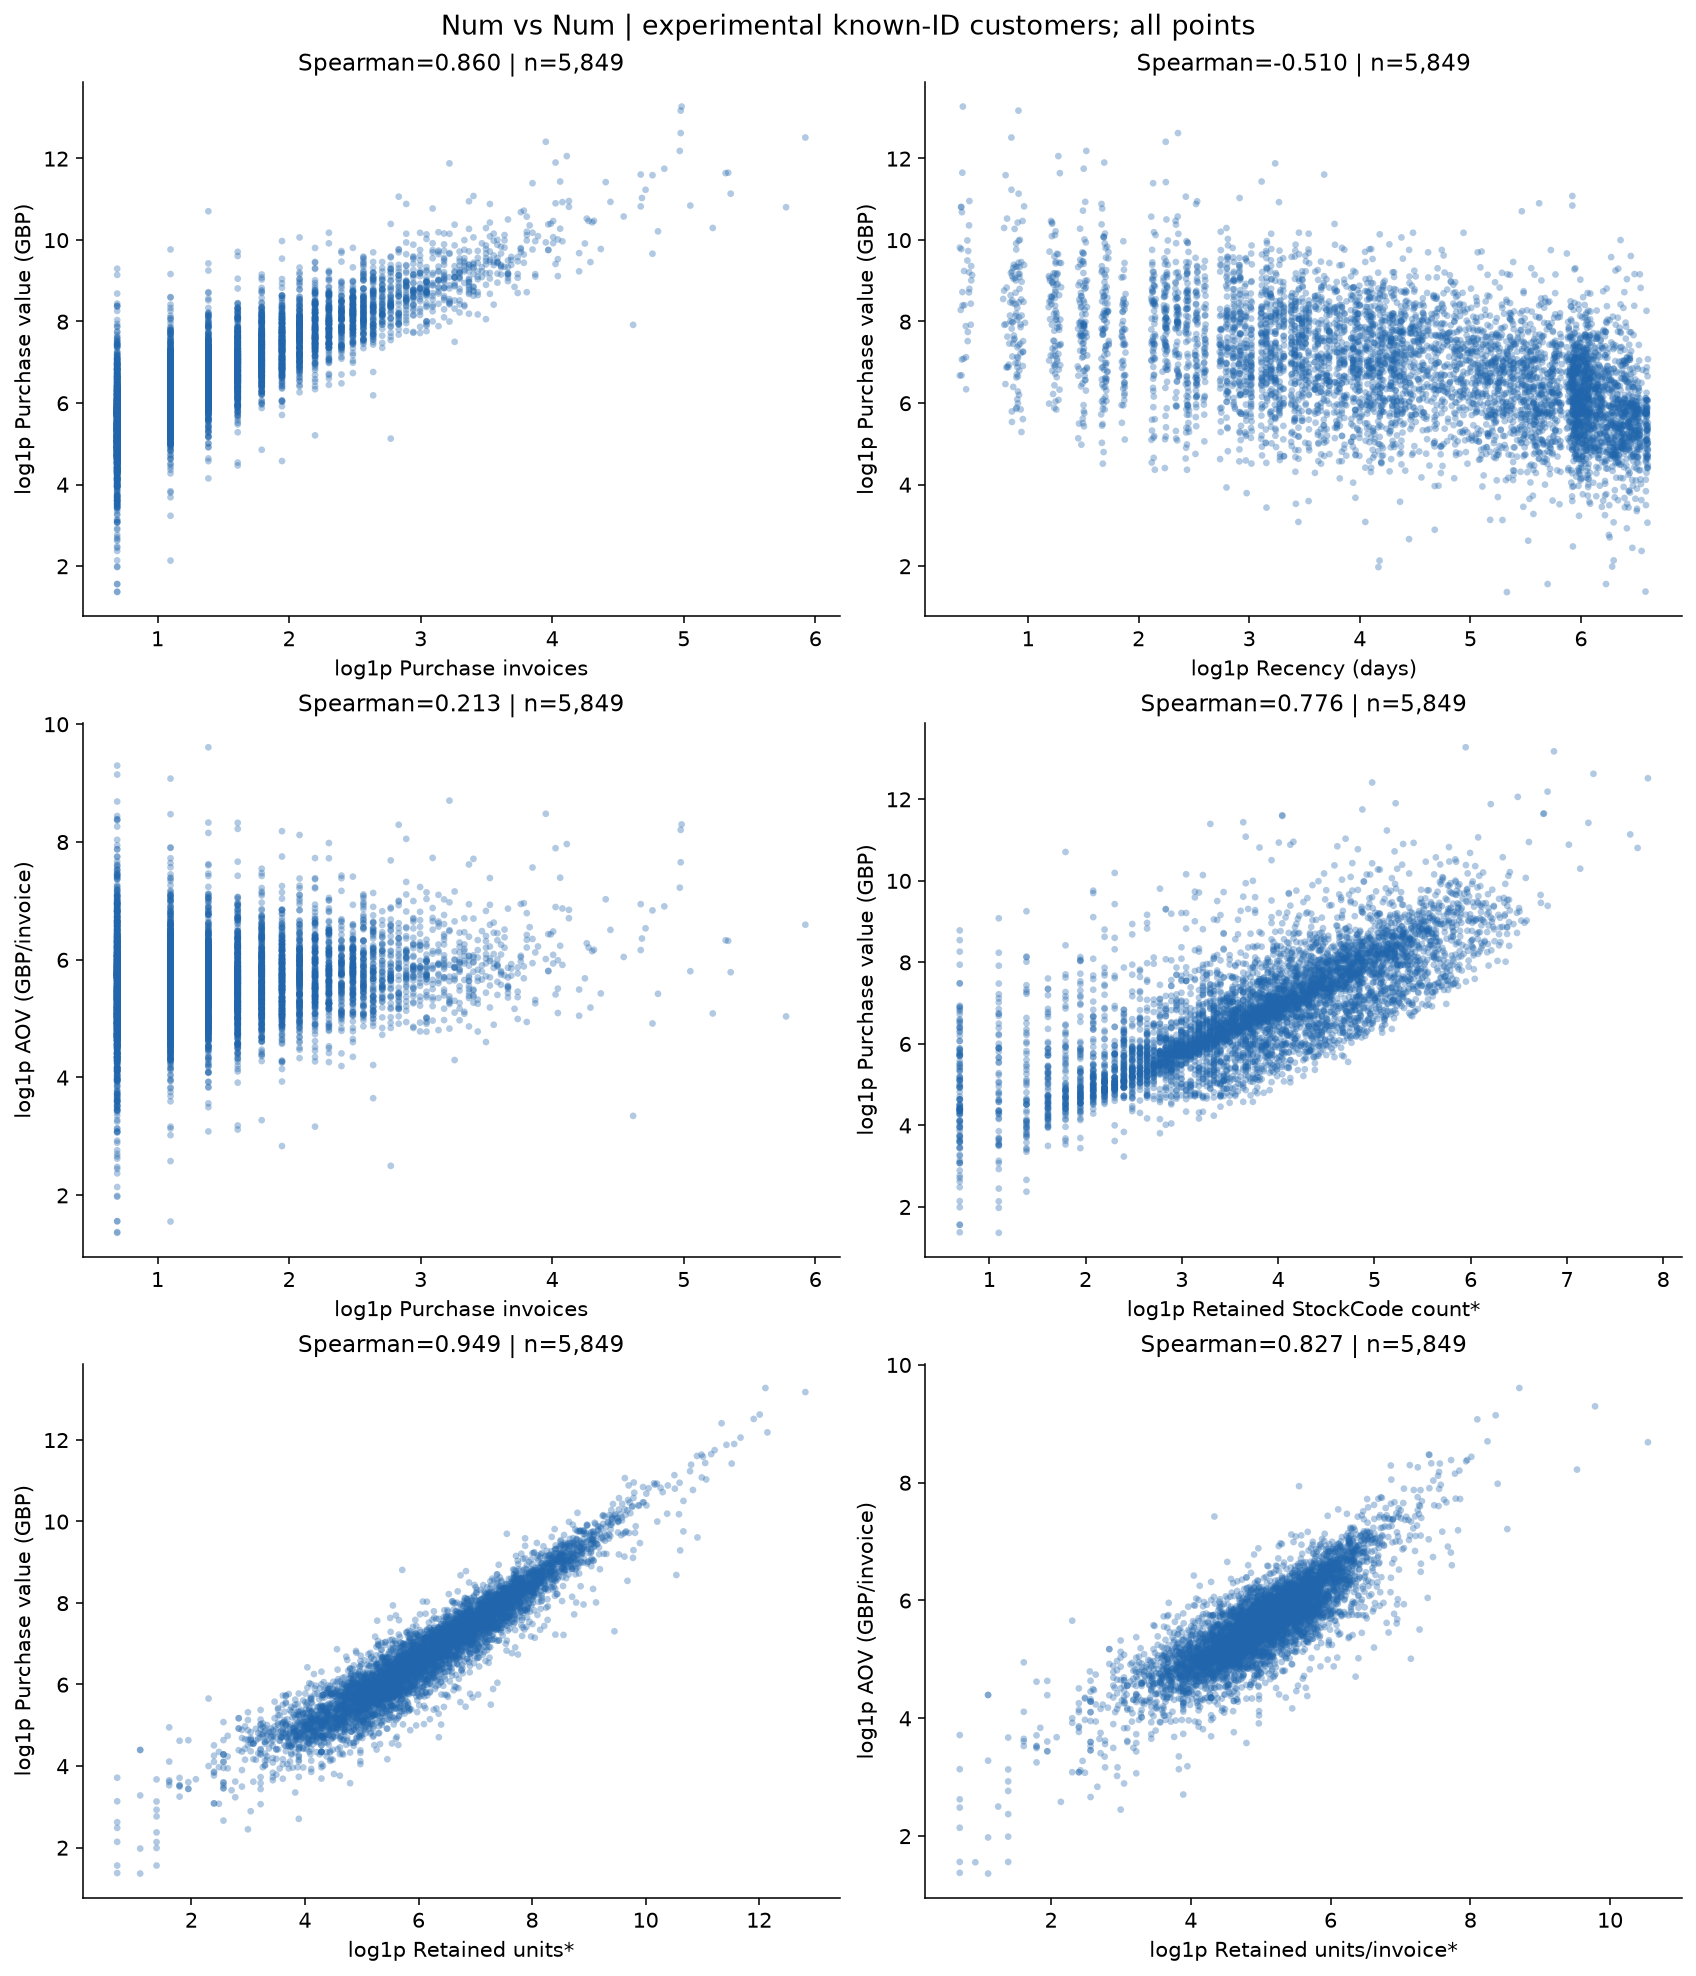

**Nhận xét:** Frequency–Monetary: Spearman=0.8603, n=5,849, xu hướng đồng biến; Recency–Monetary: Spearman=-0.5098, n=5,849, xu hướng nghịch biến; Frequency–avg_order_value: Spearman=0.2128, n=5,849, xu hướng đồng biến; n_stock_codes_candidate–Monetary: Spearman=0.7760, n=5,849, xu hướng đồng biến; total_quantity_candidate–Monetary: Spearman=0.9486, n=5,849, xu hướng đồng biến; avg_quantity_per_order_candidate–avg_order_value: Spearman=0.8272, n=5,849, xu hướng đồng biến. Scatter toàn bộ khách thể hiện cùng chiều liên hệ trên trục log1p, đồng thời còn độ phân tán lớn ở mỗi mức F.

**Ý nghĩa đối với phân cụm:** So sánh các quan hệ để cân nhắc thông tin bổ sung; F và số đơn là cùng một phép đo nên chỉ vẽ một lần.

**Giới hạn / bước tiếp theo:** M = F × AOV và giá trị từng dòng = Quantity × Price nên các biến liên hệ một phần do công thức. Log1p chỉ để hiển thị; hệ số tính trên dữ liệu gốc. Alpha giảm chồng điểm, không lấy mẫu hoặc cắt đuôi.

In [23]:
show_figure(analysis, "customer_frequency_vs_monetary")

### 6.2. Num vs Cat

In [24]:
show_tables(analysis, ['numeric_by_country', 'numeric_by_order_group'])

**numeric_by_country** — 3 dòng; đầy đủ ở `analysis['tables']['numeric_by_country']`.

,n,median_Monetary,median_Frequency,median_AOV
country_group,,,,
Multi-country,12,3797.955,7.5,424.801900
Other-country,506,1119.950,3.0,392.128333
UK,5331,824.920,3.0,268.028750


**numeric_by_order_group** — 2 dòng; đầy đủ ở `analysis['tables']['numeric_by_order_group']`.

,n,median_Monetary,median_AOV
order_group,,,
Multiple invoices,4227,1356.330,289.332308
One invoice,1622,225.885,225.885000


**Câu hỏi:** Giá trị và số đơn khác nhau giữa nhóm quốc gia/khách một đơn ra sao?

**Dữ liệu và phạm vi:** Thử nghiệm trên 5,849 khách có ID; một dòng/khách, sau clean_data hiện tại; cửa sổ [2009-12-01, 2011-12-10). Guest được loại khỏi khảo sát khách sau pipeline.

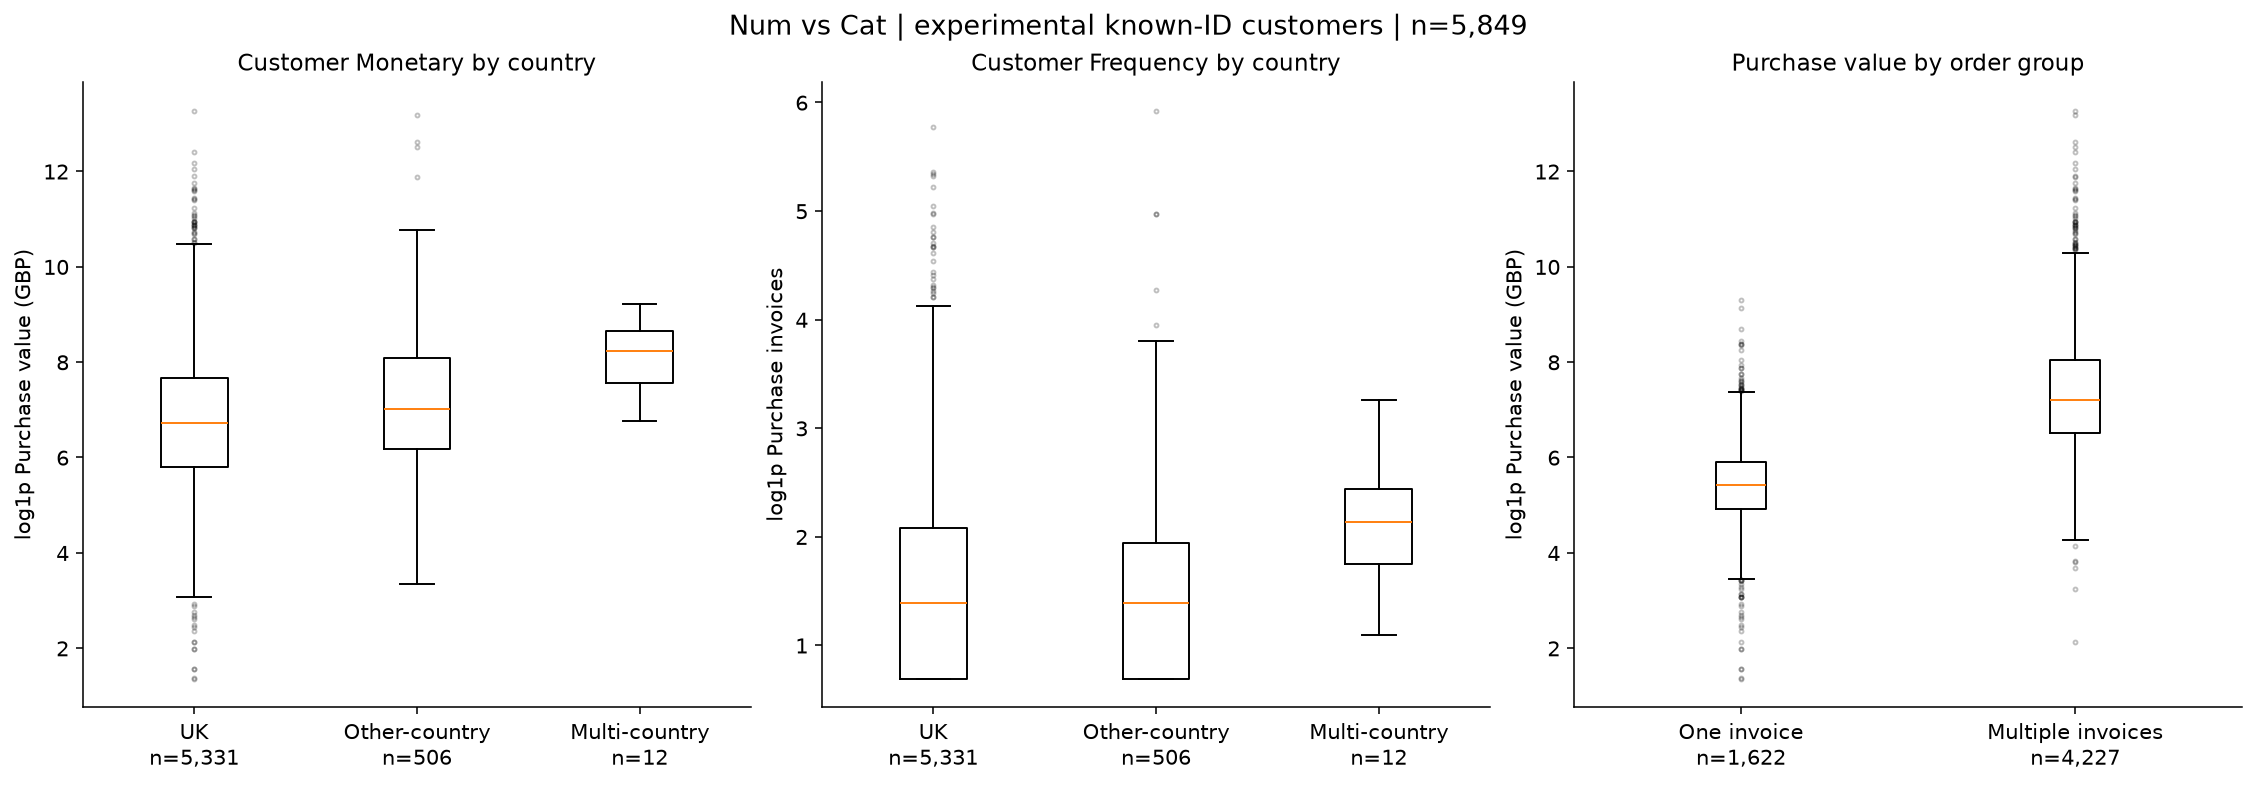

**Nhận xét:** Multi-country: n=12, median M=3,797.95 GBP, F=7.5; Other-country: n=506, median M=1,119.95 GBP, F=3.0; UK: n=5,331, median M=824.92 GBP, F=3.0; Multiple invoices: n=4,227, median M=1,356.33 GBP; One invoice: n=1,622, median M=225.88 GBP.

**Ý nghĩa đối với phân cụm:** Mô tả khác biệt phân phối, giúp kiểm tra diễn giải cụm và nhóm có lịch sử ngắn.

**Giới hạn / bước tiếp theo:** Country giữ nhãn nếu duy nhất; nhiều Country → Multi-country riêng, không gán theo tùy ý. Khách nhiều đơn được định nghĩa từ F nên chênh lệch M không là bằng chứng tác động. Nhóm ít khách không đủ suy rộng; boxplot log1p gồm mọi điểm.

In [25]:
show_figure(analysis, "customer_value_by_country")

### 6.3. Cat vs Cat

In [26]:
show_tables(analysis, ['country_invoice_counts', 'country_invoice_row_pct', 'country_order_counts', 'country_order_row_pct'])

**country_invoice_counts** — 2 dòng; đầy đủ ở `analysis['tables']['country_invoice_counts']`.

invoice_type,C,Non-C
country_group,,
Other-country,2844,83197
UK,16650,964680


**country_invoice_row_pct** — 2 dòng; đầy đủ ở `analysis['tables']['country_invoice_row_pct']`.

invoice_type,C,Non-C
country_group,,
Other-country,3.305401,96.694599
UK,1.696677,98.303323


**country_order_counts** — 3 dòng; đầy đủ ở `analysis['tables']['country_order_counts']`.

order_group,Multiple invoices,One invoice
country_group,,
Multi-country,12,0
Other-country,354,152
UK,3861,1470


**country_order_row_pct** — 3 dòng; đầy đủ ở `analysis['tables']['country_order_row_pct']`.

order_group,Multiple invoices,One invoice
country_group,,
Multi-country,100.000000,0.000000
Other-country,69.960474,30.039526
UK,72.425436,27.574564


**Câu hỏi:** Tỷ lệ dòng C thay đổi theo nhóm quốc gia không?

**Dữ liệu và phạm vi:** 1,067,371 dòng thô của hai sheet, giữ C, âm, trùng và ID thiếu.

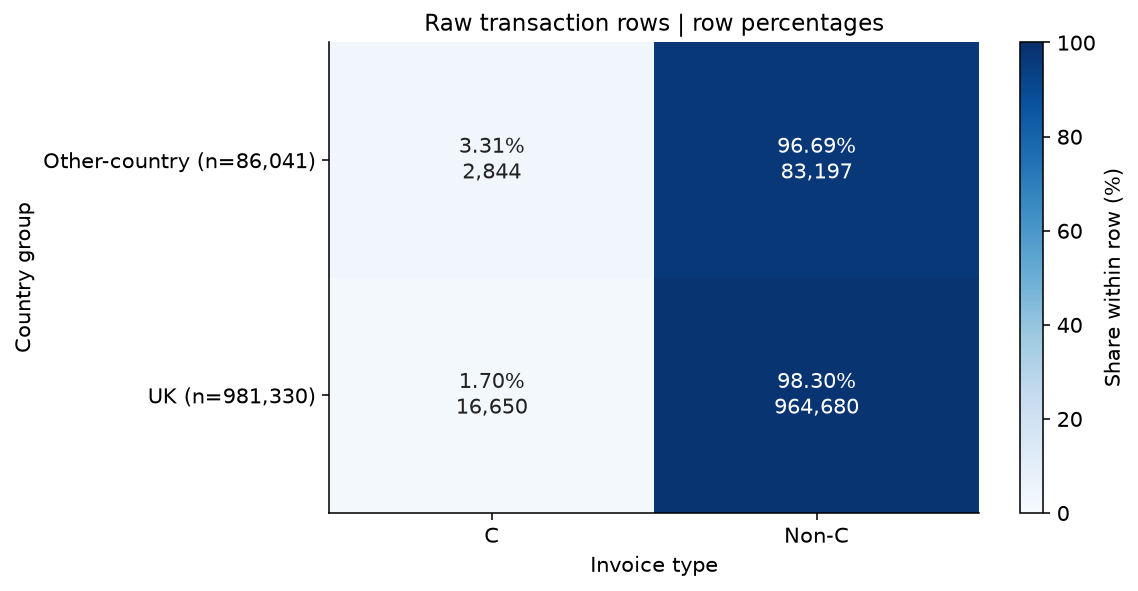

**Nhận xét:** Other-country: 2,844/86,041 = 3.31% C; UK: 16,650/981,330 = 1.70% C.

**Ý nghĩa đối với phân cụm:** Bảng chéo và tỷ lệ theo hàng cho phép so nhóm có quy mô khác nhau.

**Giới hạn / bước tiếp theo:** Mẫu số là tổng dòng trong hàng đối với loại chứng từ; tổng khách trong hàng đối với nhóm một/nhiều đơn. Đây là heatmap tỷ lệ/tần suất, không phải tương quan; không suy ra hoàn trả hay nhãn cụm.

In [27]:
show_figure(analysis, "country_vs_invoice_type")

**Câu hỏi:** Tỷ lệ khách một/nhiều đơn khác nhau giữa nhóm quốc gia không?

**Dữ liệu và phạm vi:** Thử nghiệm trên 5,849 khách có ID; một dòng/khách, sau clean_data hiện tại; cửa sổ [2009-12-01, 2011-12-10). Guest được loại khỏi khảo sát khách sau pipeline.

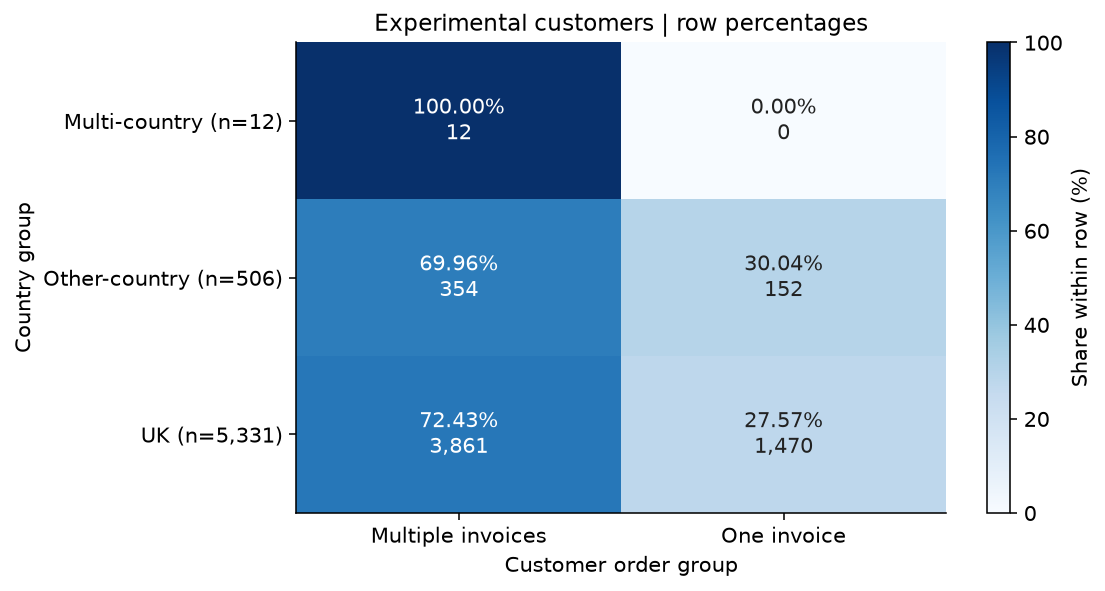

**Nhận xét:** Multi-country: 0/12 = 0.00% One invoice; Other-country: 152/506 = 30.04% One invoice; UK: 1,470/5,331 = 27.57% One invoice.

**Ý nghĩa đối với phân cụm:** Bảng chéo và tỷ lệ theo hàng cho phép so nhóm có quy mô khác nhau.

**Giới hạn / bước tiếp theo:** Mẫu số là tổng dòng trong hàng đối với loại chứng từ; tổng khách trong hàng đối với nhóm một/nhiều đơn. Đây là heatmap tỷ lệ/tần suất, không phải tương quan; không suy ra hoàn trả hay nhãn cụm.

In [28]:
show_figure(analysis, "customer_order_group_by_country")

## 7. Phân tích đa biến

**Câu hỏi:** R thay đổi thế nào đồng thời theo F và M?

**Dữ liệu và phạm vi:** Thử nghiệm trên 5,849 khách có ID; một dòng/khách, sau clean_data hiện tại; cửa sổ [2009-12-01, 2011-12-10). Guest được loại khỏi khảo sát khách sau pipeline.

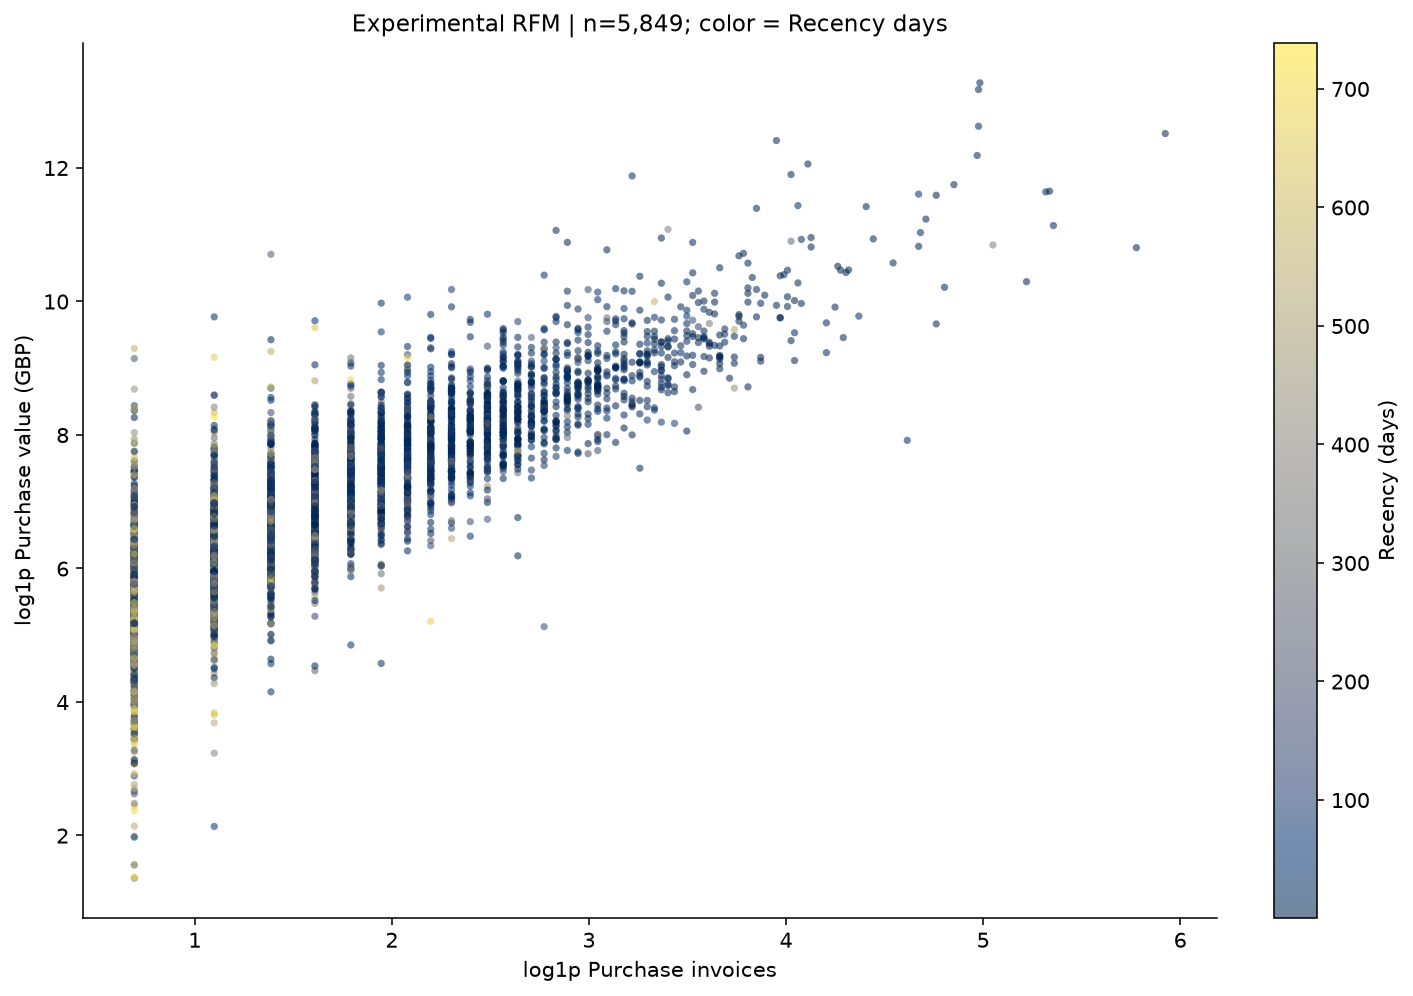

**Nhận xét:** Toàn bộ 5,849 khách được vẽ; Spearman F–M=0.8603, R–M=-0.5098, R–F=-0.5583. R từ 0.47 đến 738.55 ngày.

**Ý nghĩa đối với phân cụm:** Màu R bổ sung mức gần đây cho quan hệ F/M; cần mô hình và đánh giá độ ổn định để kiểm tra các kiểu hành vi.

**Giới hạn / bước tiếp theo:** X/Y dùng log1p, màu dùng ngày R gốc. Alpha và thứ tự điểm cố định để giảm chồng lấn, không lấy mẫu; vùng thị giác chưa phải cụm chính thức.

In [29]:
show_figure(analysis, "rfm_multivariate_scatter")

**Câu hỏi:** AOV/số mã và nhịp mua/tenure bổ sung gì cho Frequency?

**Dữ liệu và phạm vi:** Thử nghiệm trên 5,849 khách có ID; một dòng/khách, sau clean_data hiện tại; cửa sổ [2009-12-01, 2011-12-10). Guest được loại khỏi khảo sát khách sau pipeline.

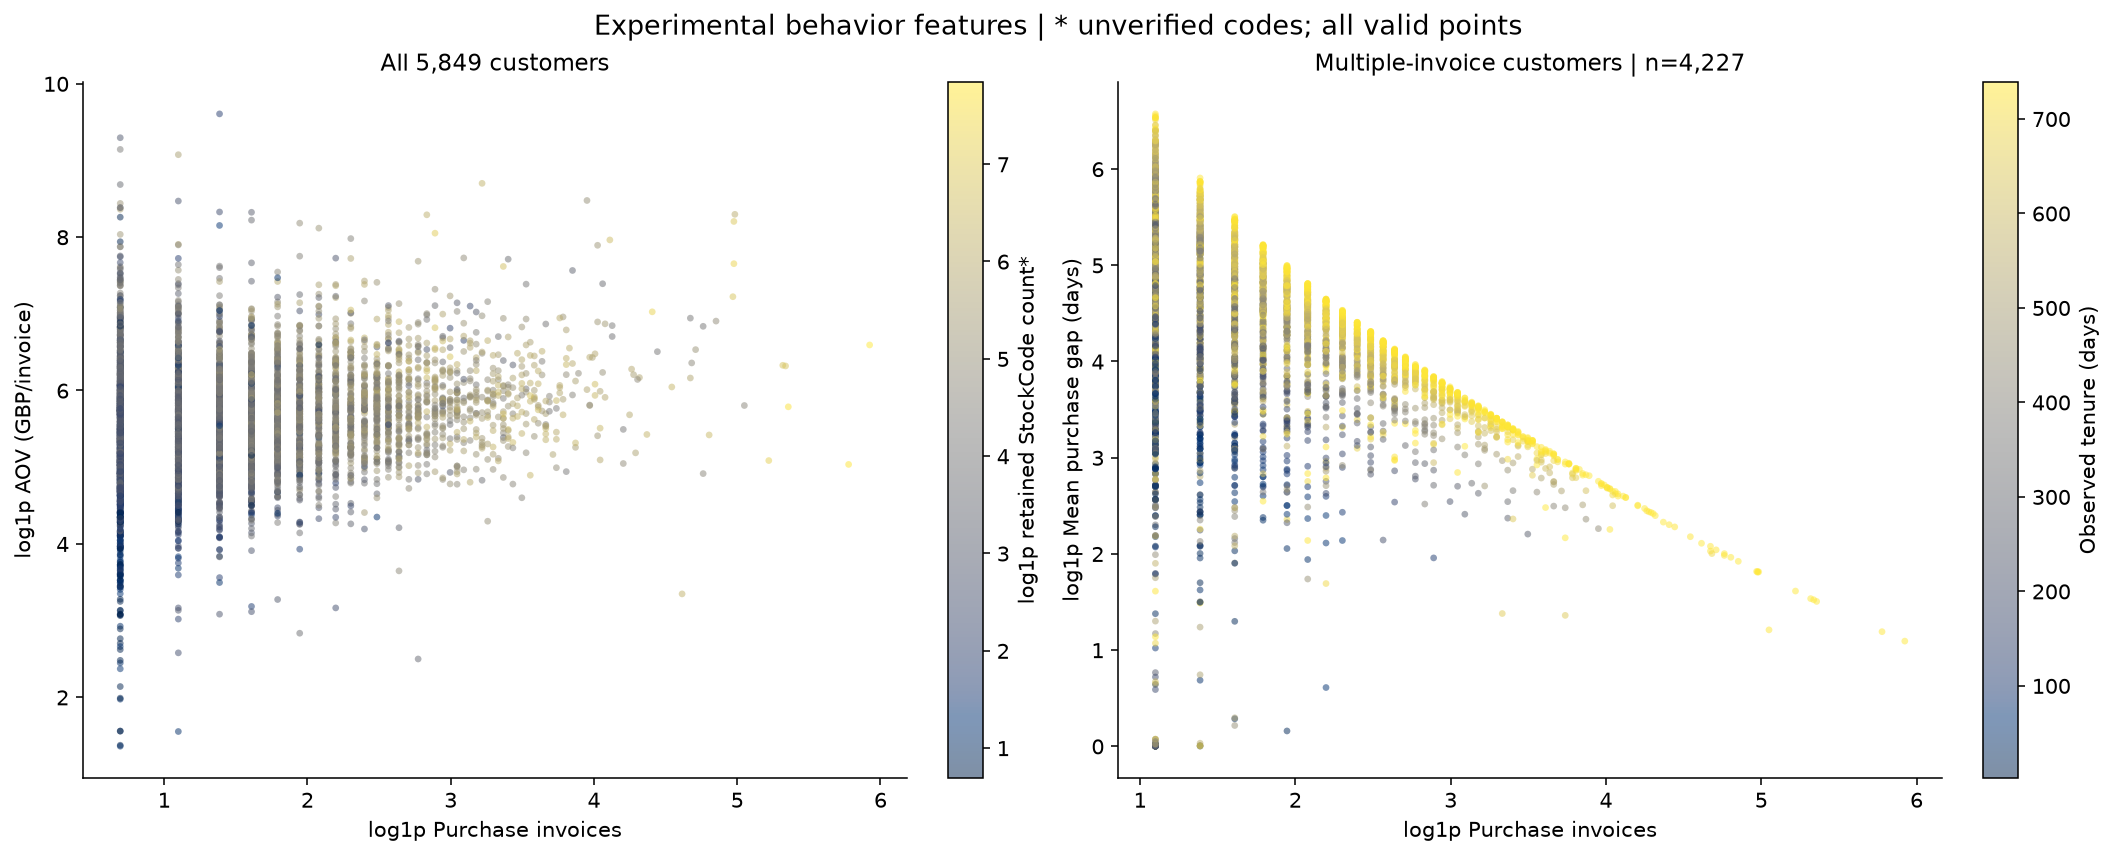

**Nhận xét:** Panel F–AOV tô màu số mã có 5,849 khách, Spearman F–AOV=0.2128; panel F–gap tô màu tenure có 4,227 khách, loại khỏi hiển thị 1,622 khách thiếu gap. Spearman F–gap=-0.4331, n=4,227.

**Ý nghĩa đối với phân cụm:** Các đặc trưng tóm tắt giỏ và nhịp mua có thể bổ sung RFM nhưng liên hệ công thức cần xem kỹ.

**Giới hạn / bước tiếp theo:** M=F×AOV; với F>1, gap=(tenure−R)/(F−1). Màu số mã hiển thị log1p; không coi các biến là độc lập hoặc đưa tất cả vào mô hình tự động.

In [30]:
show_figure(analysis, "behavior_multivariate_scatter")

**Câu hỏi:** Quan hệ F–M có cùng phạm vi giữa các nhóm quốc gia không?

**Dữ liệu và phạm vi:** Thử nghiệm trên 5,849 khách có ID; một dòng/khách, sau clean_data hiện tại; cửa sổ [2009-12-01, 2011-12-10). Guest được loại khỏi khảo sát khách sau pipeline.

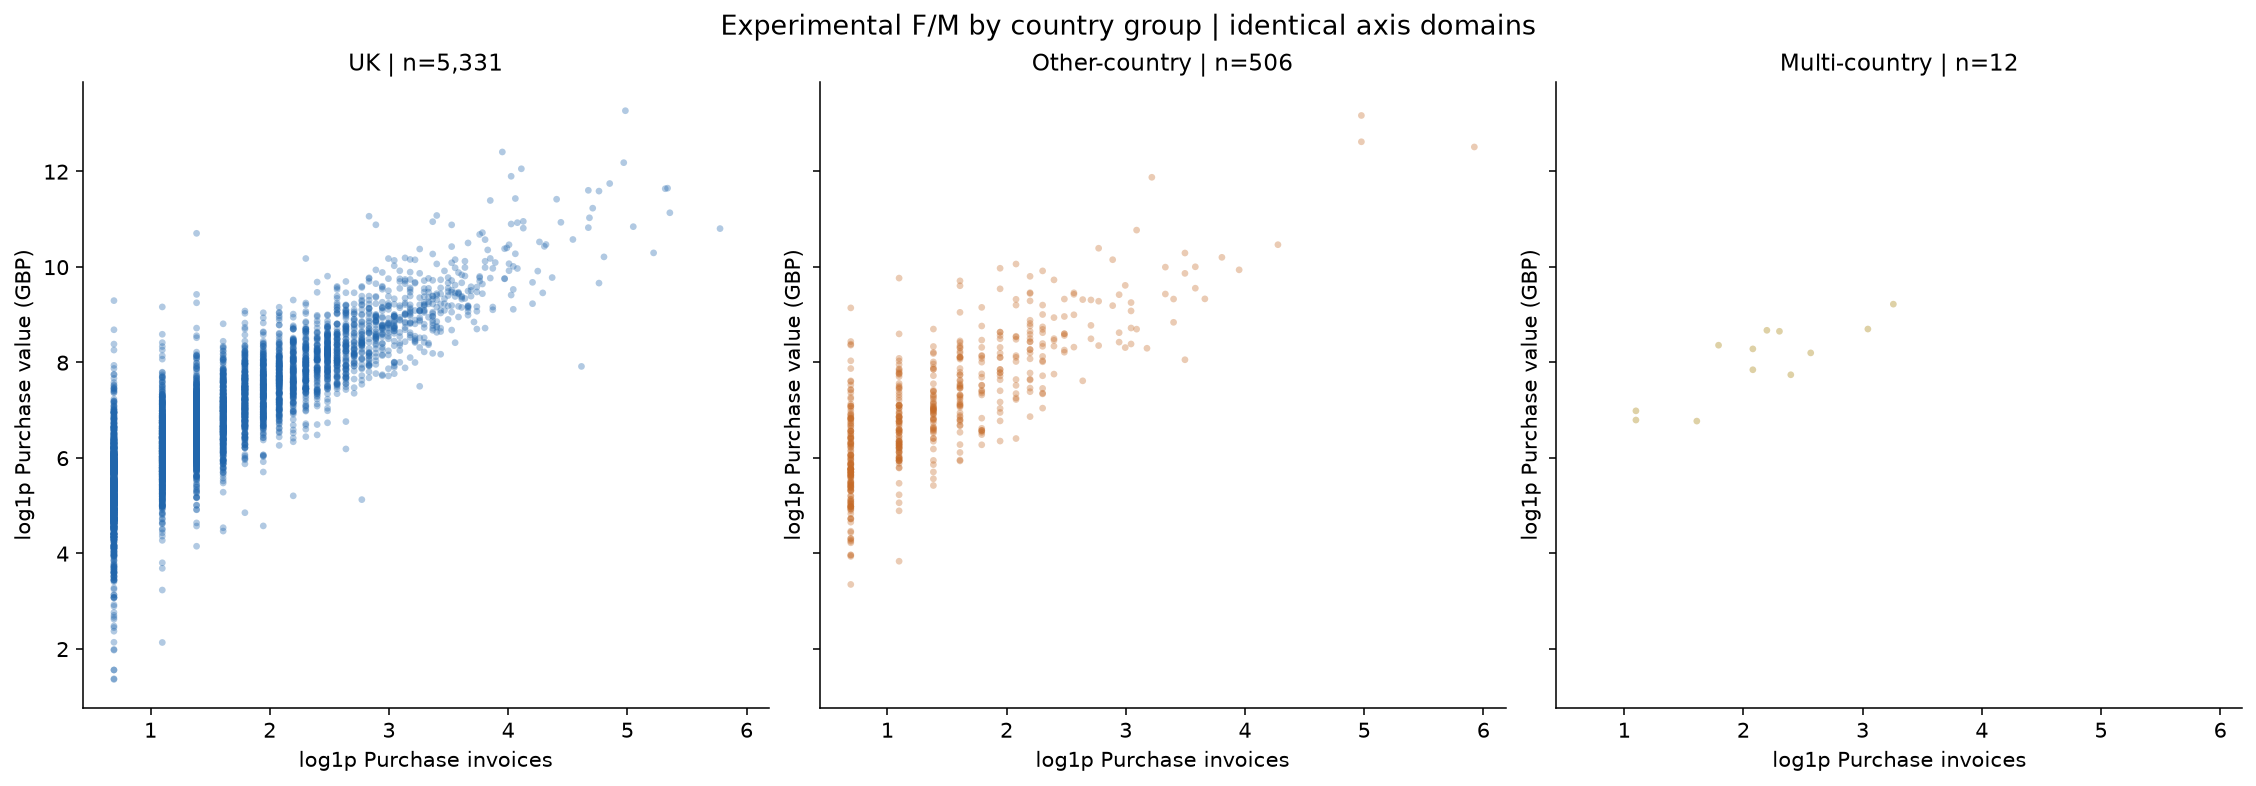

**Nhận xét:** Multi-country: n=12, median F=7.5, M=3,797.95 GBP; Other-country: n=506, median F=3.0, M=1,119.95 GBP; UK: n=5,331, median F=3.0, M=824.92 GBP. Các panel giữ chung trục log1p để so sánh miền quan sát.

**Ý nghĩa đối với phân cụm:** Kiểm tra liệu hồ sơ hành vi chỉ phản ánh quy mô thị trường; Country dùng diễn giải, chưa chọn là biến số đầu vào.

**Giới hạn / bước tiếp theo:** Multi-country được giữ thành nhóm riêng từ các dòng mua còn lại. Các nhóm quy mô khác nhau; không suy ra khác biệt có ý nghĩa thống kê hay cụm địa lý.

In [31]:
show_figure(analysis, "country_frequency_monetary")

<a id="eda-correlation"></a>

## 8. Tương quan và số quan sát hợp lệ theo cặp

In [32]:
show_tables(analysis, ['correlation_column_audit', 'correlation_spearman', 'correlation_pearson', 'correlation_pairwise_counts'])

**correlation_column_audit** — 14 dòng; đầy đủ ở `analysis['tables']['correlation_column_audit']`.

,variable,status,valid,missing,unique
0,Recency,included,5849,0,5699
1,Frequency,included,5849,0,86
2,Monetary,included,5849,0,5750
3,avg_order_value,included,5849,0,5758
4,avg_purchase_gap_days,included,4227,1622,4199
5,observed_tenure_days,included,5849,0,5737
6,n_stock_codes_candidate,included,5849,0,458
7,total_quantity_candidate,included,5849,0,2348
8,avg_quantity_per_order_candidate,included,5849,0,3040
9,n_distinct_products,all_missing,0,5849,0


**correlation_spearman** — 9 dòng; đầy đủ ở `analysis['tables']['correlation_spearman']`.

,Recency,Frequency,Monetary,avg_order_value,avg_purchase_gap_days,observed_tenure_days,n_stock_codes_candidate,total_quantity_candidate,avg_quantity_per_order_candidate
Recency,1.000000,-0.558285,-0.509819,-0.172035,0.162975,0.152814,-0.466763,-0.512342,-0.191877
Frequency,-0.558285,1.000000,0.860283,0.212846,-0.433051,0.500407,0.722244,0.819396,0.179604
Monetary,-0.509819,0.860283,1.000000,0.651551,-0.353176,0.424206,0.776023,0.948603,0.546166
avg_order_value,-0.172035,0.212846,0.651551,1.000000,-0.050077,0.095733,0.430317,0.616608,0.827242
avg_purchase_gap_days,0.162975,-0.433051,-0.353176,-0.050077,1.000000,0.131704,-0.243780,-0.335864,-0.036555
observed_tenure_days,0.152814,0.500407,0.424206,0.095733,0.131704,1.000000,0.346809,0.384393,0.035760
n_stock_codes_candidate,-0.466763,0.722244,0.776023,0.430317,-0.243780,0.346809,1.000000,0.762720,0.406912
total_quantity_candidate,-0.512342,0.819396,0.948603,0.616608,-0.335864,0.384393,0.762720,1.000000,0.681362
avg_quantity_per_order_candidate,-0.191877,0.179604,0.546166,0.827242,-0.036555,0.035760,0.406912,0.681362,1.000000


**correlation_pearson** — 9 dòng; đầy đủ ở `analysis['tables']['correlation_pearson']`.

,Recency,Frequency,Monetary,avg_order_value,avg_purchase_gap_days,observed_tenure_days,n_stock_codes_candidate,total_quantity_candidate,avg_quantity_per_order_candidate
Recency,1.000000,-0.258610,-0.124917,-0.058346,-0.029656,0.283989,-0.322338,-0.124838,-0.011419
Frequency,-0.258610,1.000000,0.629362,0.102903,-0.259481,0.276160,0.690943,0.621952,0.034952
Monetary,-0.124917,0.629362,1.000000,0.329971,-0.129440,0.133370,0.410606,0.929404,0.134171
avg_order_value,-0.058346,0.102903,0.329971,1.000000,-0.029527,0.018457,0.167084,0.330516,0.585618
avg_purchase_gap_days,-0.029656,-0.259481,-0.129440,-0.029527,1.000000,0.162943,-0.230645,-0.131406,-0.025489
observed_tenure_days,0.283989,0.276160,0.133370,0.018457,0.162943,1.000000,0.275926,0.136203,0.004683
n_stock_codes_candidate,-0.322338,0.690943,0.410606,0.167084,-0.230645,0.275926,1.000000,0.428182,0.064642
total_quantity_candidate,-0.124838,0.621952,0.929404,0.330516,-0.131406,0.136203,0.428182,1.000000,0.234325
avg_quantity_per_order_candidate,-0.011419,0.034952,0.134171,0.585618,-0.025489,0.004683,0.064642,0.234325,1.000000


**correlation_pairwise_counts** — 9 dòng; đầy đủ ở `analysis['tables']['correlation_pairwise_counts']`.

,Recency,Frequency,Monetary,avg_order_value,avg_purchase_gap_days,observed_tenure_days,n_stock_codes_candidate,total_quantity_candidate,avg_quantity_per_order_candidate
Recency,5849,5849,5849,5849,4227,5849,5849,5849,5849
Frequency,5849,5849,5849,5849,4227,5849,5849,5849,5849
Monetary,5849,5849,5849,5849,4227,5849,5849,5849,5849
avg_order_value,5849,5849,5849,5849,4227,5849,5849,5849,5849
avg_purchase_gap_days,4227,4227,4227,4227,4227,4227,4227,4227,4227
observed_tenure_days,5849,5849,5849,5849,4227,5849,5849,5849,5849
n_stock_codes_candidate,5849,5849,5849,5849,4227,5849,5849,5849,5849
total_quantity_candidate,5849,5849,5849,5849,4227,5849,5849,5849,5849
avg_quantity_per_order_candidate,5849,5849,5849,5849,4227,5849,5849,5849,5849


**Câu hỏi:** Spearman cho thấy cặp nào liên hệ hoặc trùng thông tin?

**Dữ liệu và phạm vi:** Thử nghiệm trên 5,849 khách có ID; một dòng/khách, sau clean_data hiện tại; cửa sổ [2009-12-01, 2011-12-10). Guest được loại khỏi khảo sát khách sau pipeline. Chỉ 9 biến số cùng phạm vi; pairwise complete observations.

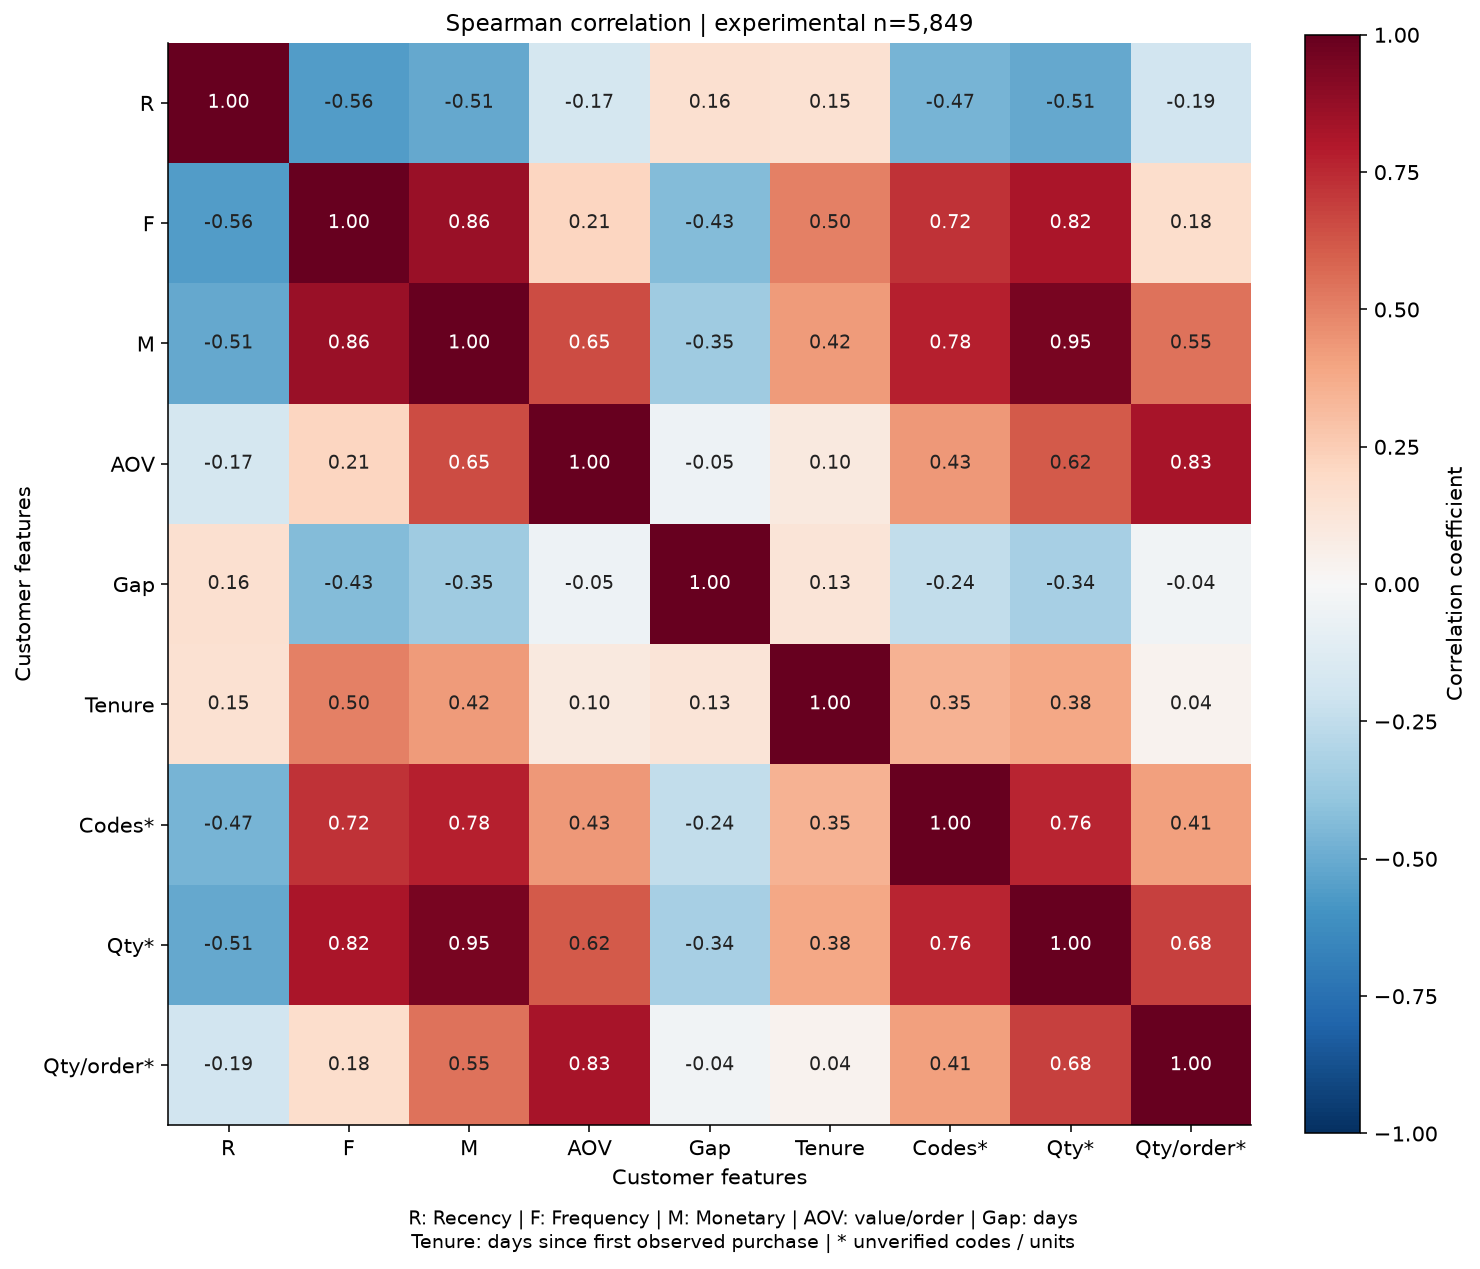

**Nhận xét:** Spearman F–M=0.8603 (n=5,849); R–M=-0.5098 (n=5,849); F–gap=-0.4331 (n=4,227). Có 4 cột thiếu toàn bộ và 1 cột không phải số bị loại trước tính; 0 cột hằng trong dữ liệu thực tế.

**Ý nghĩa đối với phân cụm:** Spearman xem quan hệ đơn điệu; Pearson nhạy đuôi lớn. Cân nhắc trùng thông tin với công thức M=F×AOV và Q=F×Q/đơn; không tự động loại biến chỉ vì hệ số cao.

**Giới hạn / bước tiếp theo:** Không điền NaN bằng 0. Mỗi cặp có thể dùng tập khách khác; không diễn giải tương quan như nhân quả hay bằng chứng chất lượng phân cụm. R/F/M không chứa ID, timestamp hoặc nhãn Country.

In [33]:
show_figure(analysis, "correlation_spearman_heatmap")

**Câu hỏi:** Pearson cho thấy cặp nào liên hệ hoặc trùng thông tin?

**Dữ liệu và phạm vi:** Thử nghiệm trên 5,849 khách có ID; một dòng/khách, sau clean_data hiện tại; cửa sổ [2009-12-01, 2011-12-10). Guest được loại khỏi khảo sát khách sau pipeline. Chỉ 9 biến số cùng phạm vi; pairwise complete observations.

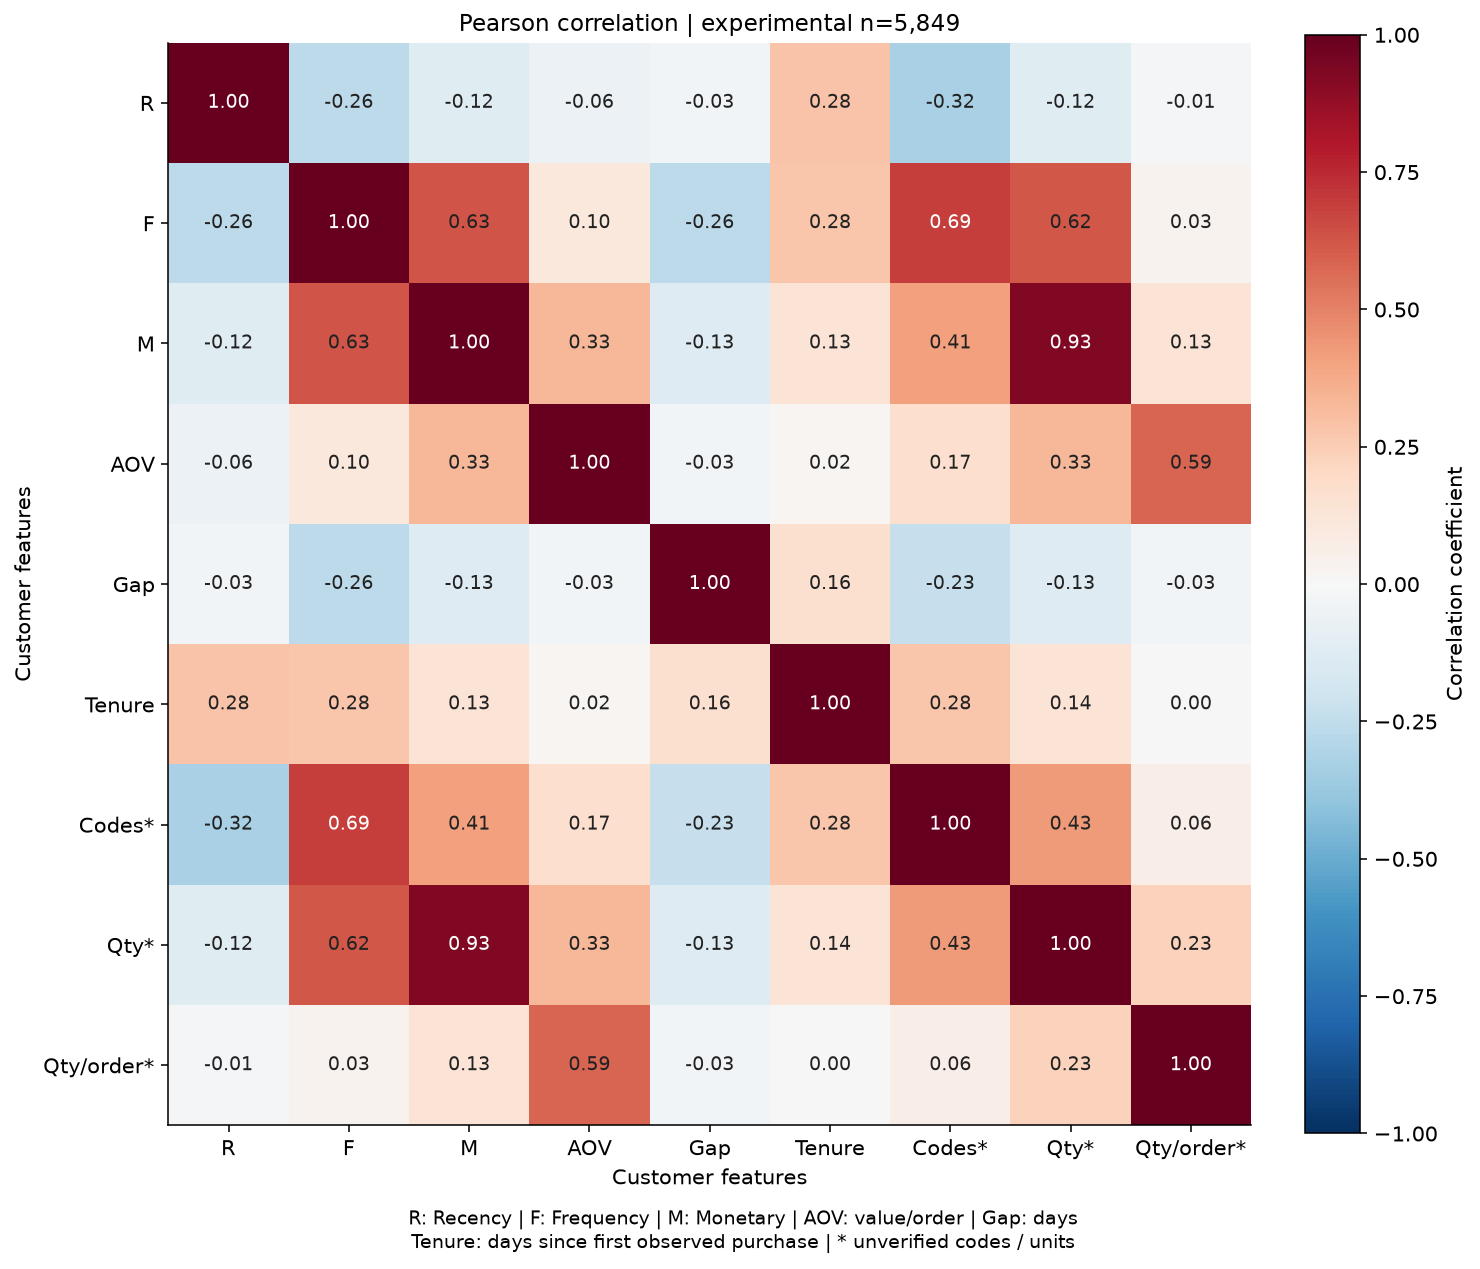

**Nhận xét:** Pearson F–M=0.6294 (n=5,849); R–M=-0.1249 (n=5,849); F–gap=-0.2595 (n=4,227). Có 4 cột thiếu toàn bộ và 1 cột không phải số bị loại trước tính; 0 cột hằng trong dữ liệu thực tế.

**Ý nghĩa đối với phân cụm:** Spearman xem quan hệ đơn điệu; Pearson nhạy đuôi lớn. Cân nhắc trùng thông tin với công thức M=F×AOV và Q=F×Q/đơn; không tự động loại biến chỉ vì hệ số cao.

**Giới hạn / bước tiếp theo:** Không điền NaN bằng 0. Mỗi cặp có thể dùng tập khách khác; không diễn giải tương quan như nhân quả hay bằng chứng chất lượng phân cụm. R/F/M không chứa ID, timestamp hoặc nhãn Country.

In [34]:
show_figure(analysis, "correlation_pearson_heatmap")

**Câu hỏi:** Mỗi hệ số có bao nhiêu khách hợp lệ?

**Dữ liệu và phạm vi:** Thử nghiệm trên 5,849 khách có ID; một dòng/khách, sau clean_data hiện tại; cửa sổ [2009-12-01, 2011-12-10). Guest được loại khỏi khảo sát khách sau pipeline.

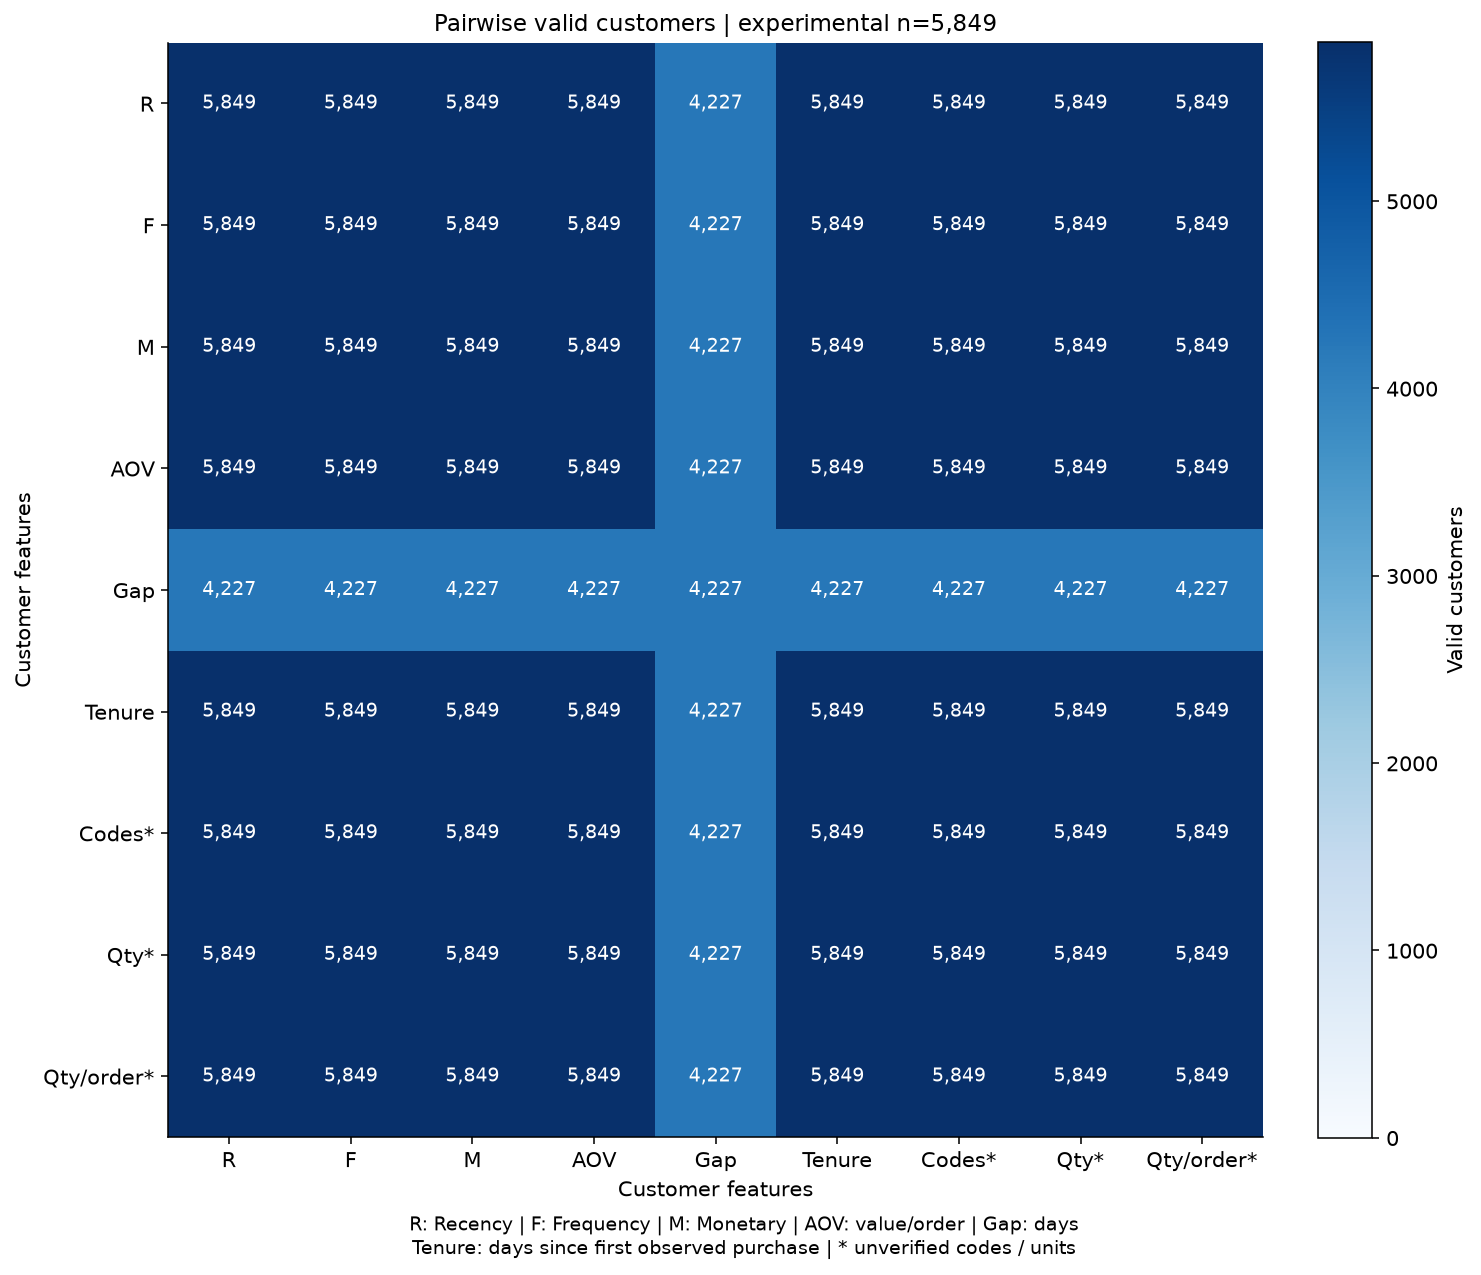

**Nhận xét:** Cặp không chứa gap có 5,849 quan sát; các cặp chứa gap có 4,227. Chênh 1,622 chính là khách một Invoice; đường chéo gap cũng 4,227.

**Ý nghĩa đối với phân cụm:** Đọc n cùng hệ số; các hệ số chứa gap chỉ mô tả khách mua nhiều đơn, có thể chịu sai lệch chọn mẫu.

**Giới hạn / bước tiếp theo:** Ma trận n dùng số nguyên int64 và giao hai cờ hữu hạn, không dùng len toàn bảng cho mọi cặp. NaN vẫn là chưa quan sát, không phải nhịp mua 0.

In [35]:
show_figure(analysis, "correlation_pairwise_counts")

<a id="eda-outliers"></a>

## 9. Độ lệch và ngoại lệ

### 9.1. IQR ở cấp giao dịch

Câu hỏi: biến nào có nhiều dòng vượt râu Tukey 1.5×IQR?
Giữ riêng thô và đầu ra pipeline. [Histogram/boxplot ở mục 3](#eda-distributions)
đã mô tả toàn miền; phần này tập trung ngưỡng và số điểm cần điều tra.


In [36]:
iqr_columns = ["population", "variable", "count", "iqr_lower", "iqr_upper",
               "outside_iqr", "outside_iqr_pct"]
display(tables["transaction_profile"][iqr_columns])


,population,variable,count,iqr_lower,iqr_upper,outside_iqr,outside_iqr_pct
0,raw_including_C,Quantity,1067371,-12.500,23.500,116489,10.913637
1,raw_including_C,Price,1067371,-3.100,8.500,68105,6.380631
2,raw_including_C,LineValue,1067371,-17.175,38.625,90922,8.518313
3,current_pipeline_including_Guest,Quantity,1002995,-15.500,28.500,52955,5.279687
4,current_pipeline_including_Guest,Price,1002995,-3.070,8.450,74757,7.453377
5,current_pipeline_including_Guest,LineValue,1002995,-16.225,38.055,81705,8.146102


In [37]:
profile = tables["transaction_profile"]
for scope, group in profile.groupby("population", sort=False):
    most = group.loc[group.outside_iqr_pct.idxmax()]
    display(Markdown(f"**{scope}:** {most.variable} có tỷ lệ gắn cờ cao nhất, "
                     f"{int(most.outside_iqr):,}/{int(most['count']):,} dòng "
                     f"({most.outside_iqr_pct:.2f}%). Đây là ngưỡng điều tra, chưa xác minh lỗi."))


**raw_including_C:** Quantity có tỷ lệ gắn cờ cao nhất, 116,489/1,067,371 dòng (10.91%). Đây là ngưỡng điều tra, chưa xác minh lỗi.

**current_pipeline_including_Guest:** LineValue có tỷ lệ gắn cờ cao nhất, 81,705/1,002,995 dòng (8.15%). Đây là ngưỡng điều tra, chưa xác minh lỗi.

### 9.2. Mẫu cực trị cần đối chiếu

Các mẫu thuộc cùng dữ liệu/cửa sổ của lần chạy này, không đại diện toàn bộ phân phối.
Cặp mua/C đối dấu chỉ hỗ trợ điều tra, chưa xác minh hoàn trả. Phân biệt lỗi có bằng chứng,
giá trị đặc biệt do nghiệp vụ, khách lớn hợp lệ và điểm được IQR đánh dấu.


In [38]:
display(tables["extreme_rows"][["variable", "direction", "Invoice", "StockCode",
                                "Quantity", "Price", "LineValue", "InvoiceDate"]])


,variable,direction,Invoice,StockCode,Quantity,Price,LineValue,InvoiceDate
1065883,Quantity,smallest,C581484,23843,-80995,2.08,-168469.60,2011-12-09 09:27:00
587085,Quantity,smallest,C541433,23166,-74215,1.04,-77183.60,2011-01-18 10:17:00
179403,Price,smallest,A506401,B,1,-53594.36,-53594.36,2010-04-29 13:36:00
276274,Price,smallest,A516228,B,1,-44031.79,-44031.79,2010-07-19 11:24:00
1065883,LineValue,smallest,C581484,23843,-80995,2.08,-168469.60,2011-12-09 09:27:00
587085,LineValue,smallest,C541433,23166,-74215,1.04,-77183.60,2011-01-18 10:17:00
1065882,Quantity,largest,581483,23843,80995,2.08,168469.60,2011-12-09 09:15:00
587080,Quantity,largest,541431,23166,74215,1.04,77183.60,2011-01-18 10:01:00
748142,Price,largest,C556445,M,-1,38970.00,-38970.00,2011-06-10 15:31:00
241824,Price,largest,C512770,M,-1,25111.09,-25111.09,2010-06-17 16:52:00


### 9.3. IQR ở cấp khách hàng

Mỗi khách một dòng. Đọc cùng [phân phối hành vi](#eda-distributions) và
[quan hệ giữa các biến](#eda-relationships). Bảng dưới tập trung tỷ lệ khách cần kiểm tra,
không lập danh sách loại khách tự động.


In [39]:
customer = tables["customer_behavior"]
customer_iqr = tables["customer_profile"]
display(customer_iqr[["variable", "count", "iqr_lower", "iqr_upper", "p99",
                      "maximum", "outside_iqr", "outside_iqr_pct"]])
monetary = customer_iqr.set_index("variable").loc["Monetary"]
display(Markdown(f"**Giá trị mua:** {int(monetary.outside_iqr):,}/{len(customer):,} khách "
                 f"vượt ngưỡng IQR ({monetary.outside_iqr_pct:.2f}%); "
                 f"Monetary lớn nhất {monetary.maximum:,.2f} GBP. "
                 "Chưa có bằng chứng để coi mọi khách này là lỗi."))


,variable,count,iqr_lower,iqr_upper,p99,maximum,outside_iqr,outside_iqr_pct
0,Recency,5849,-505.414931,910.271181,726.347889,738.549306,0,0.000000
1,Frequency,5849,-8.000000,16.000000,46.000000,373.000000,423,7.232005
2,Monetary,5849,-2509.935000,5077.945000,26295.099600,580987.040000,616,10.531715
3,avg_order_value,5849,-175.902000,760.370000,1747.402560,14844.766667,374,6.394255
4,avg_purchase_gap_days,4227,-98.512674,268.623715,487.195333,714.152083,307,7.262834
5,observed_tenure_days,5849,-221.154514,1199.242708,738.424667,738.677083,0,0.000000
6,n_stock_codes_candidate,5849,-107.000000,229.000000,503.040000,2542.000000,451,7.710720
7,total_quantity_candidate,5849,-1554.000000,3094.000000,16383.320000,367066.000000,600,10.258164
8,avg_quantity_per_order_candidate,5849,-159.208333,511.125000,1274.080000,37847.000000,356,6.086511


**Giá trị mua:** 616/5,849 khách vượt ngưỡng IQR (10.53%); Monetary lớn nhất 580,987.04 GBP. Chưa có bằng chứng để coi mọi khách này là lỗi.

Pipeline của Thuận đã lọc log-IQR k=3 ở cấp dòng; IQR1.5 trong EDA là phép khảo sát khác.
Không xóa thêm khách hoặc winsorize. Cần nhóm đánh giá độ nhạy và xác nhận chính sách ngoại lệ.
Gap của khách một đơn vẫn là NaN, không thành 0; nguồn sản phẩm/hoàn trả chưa xác minh vẫn giữ thiếu.


## 10. Đối chiếu tiền xử lý trước và sau

Đối chiếu cùng mã clean_data nguyên trạng, số dòng/hóa đơn/khách sau từng bước và đầu ra lịch sử.
Không coi khác chính sách là thay đổi hành vi khách theo thời gian.


In [40]:
show_tables(analysis, ["policy_settings", "preprocessing_trace", "stored_comparison"])

**policy_settings** — 6 dòng; đầy đủ ở `analysis['tables']['policy_settings']`.

,setting,value
0,API,src.preprocessing.clean_data
1,SPECIAL_CODES,"ADJUST, ADJUST2, AMAZONFEE, B, BANK CHARGES, C..."
2,Pipeline outlier,"log1p ['Quantity', 'Price']; k=3.0"
3,Customer EDA,Exclude Guest AFTER pipeline; same window for ...
4,Invoice time,earliest within retained purchase rows
5,Status,experimental_current_code_not_official_policy


**preprocessing_trace** — 9 dòng; đầy đủ ở `analysis['tables']['preprocessing_trace']`.

,step,rows,invoices,known_customers,anonymous_rows,reason,removed_rows
0,Dữ liệu thô,1067371,53628,5942,243007,Gộp đúng 8 cột nguồn; không đưa Sheet vào khóa...,0
1,Chuẩn hóa văn bản,1067371,53628,5942,243007,Description thiếu được điền; EIRE → Ireland,0
2,Sau bỏ trùng đã chuẩn hóa,1033036,53628,5942,235151,Quy tắc mã hiện tại; không khẳng định mọi trùn...,34335
3,Sau bỏ chứng từ C,1013932,45336,5881,234437,Không ghép C với đơn gốc trong chính sách hiện...,19104
4,Sau giữ Q/P dương,1007913,40077,5878,228488,Quantity > 0 và Price > 0,6019
5,Sau bỏ mã đặc biệt,1003434,39516,5852,226838,Danh sách SPECIAL_CODES hiện tại; chưa phải da...,4479
6,Sau lọc ngoại lệ của pipeline,1002995,39459,5849,226757,IQR × 3 trên log1p Quantity/Price; bao gồm cả ...,439
7,Đầu ra clean_data (có Guest),1002995,39459,5849,226757,"Guest là nhãn dòng vô danh, không phải một khá...",0
8,Tập khảo sát khách có ID,776238,36547,5849,0,Lựa chọn EDA sau pipeline; không sửa quy tắc G...,226757


**stored_comparison** — 3 dòng; đầy đủ ở `analysis['tables']['stored_comparison']`.

,artifact,rows,customers,columns,status
0,data/processed/online_retail_clean.csv.gz,770606,5839,Invoice; StockCode; Description; Quantity; Inv...,historical_scope_not_equivalent_to_current_run
1,experiments/eda_rebuild/tables/customer_behavi...,5839,5839,Customer ID; n_transaction_rows; n_orders; avg...,historical_scope_not_equivalent_to_current_run
2,experiments/form2_manual_behavior_raw_survey/c...,5878,5878,Customer ID; n_transaction_rows; n_orders; avg...,historical_scope_not_equivalent_to_current_run


**Câu hỏi:** Mỗi bước mã hiện tại giữ lại bao nhiêu dòng/hóa đơn/khách?

**Dữ liệu và phạm vi:** 1,067,371 dòng thô của hai sheet, giữ C, âm, trùng và ID thiếu. Chạy clean_data nguyên trạng và đối chiếu trace độc lập, không ghi processed.

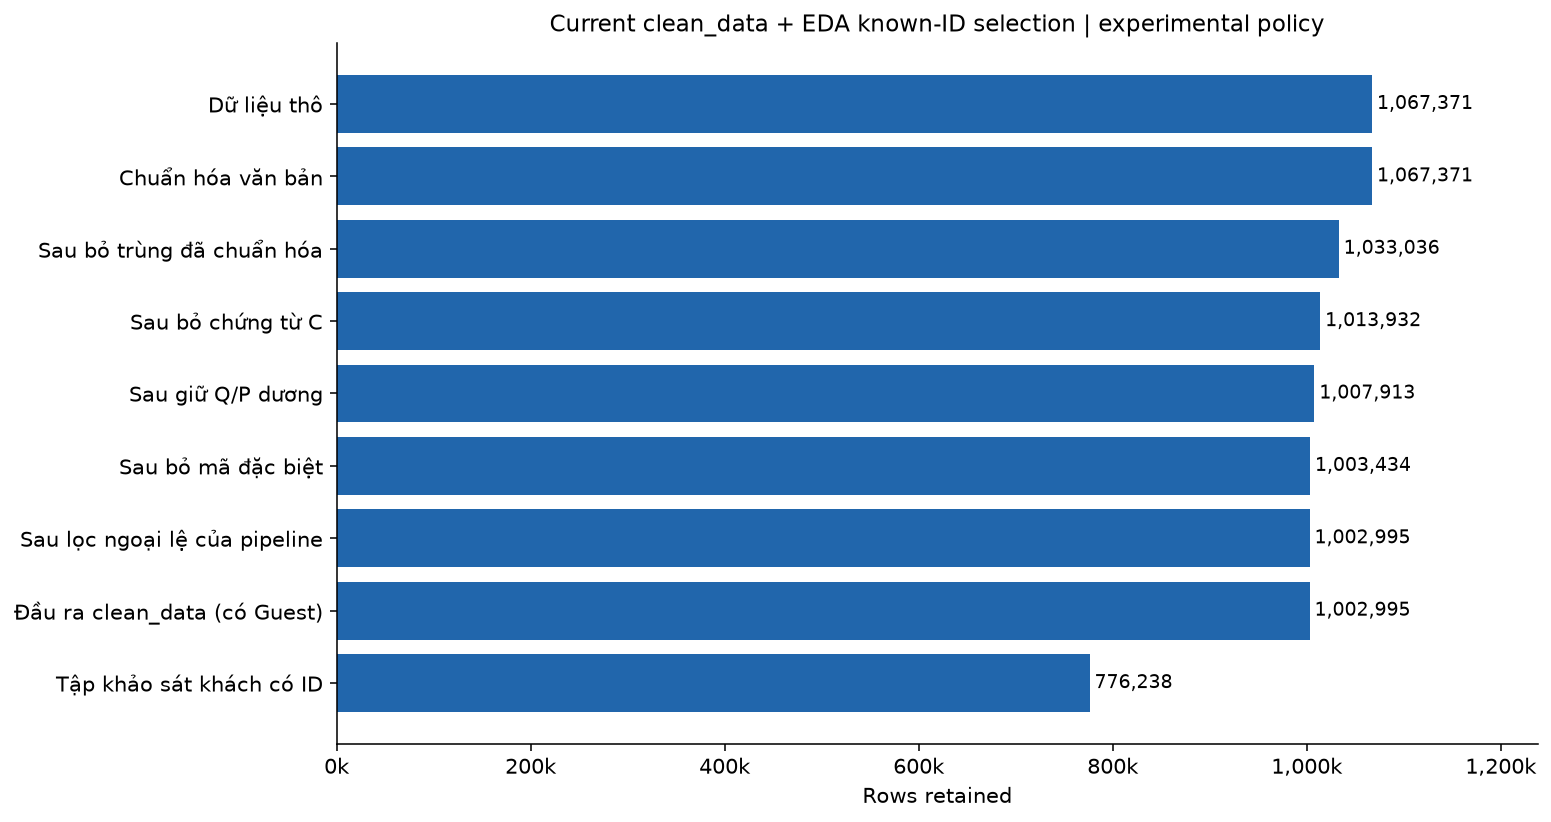

**Nhận xét:** 1,067,371 dòng thô → 1,002,995 dòng đầu ra pipeline (có 226,757 dòng Guest) → 776,238 dòng khảo sát ID thật, 36,547 hóa đơn, 5,849 khách. Bước log-IQR loại 439 dòng.

**Ý nghĩa đối với phân cụm:** Đếm riêng khách định danh và dòng Guest; đầu ra cũ trong processed không tương đương lần chạy này.

**Giới hạn / bước tiếp theo:** Đã xác minh khớp mã hiện tại, chưa có bằng chứng chính sách được phê duyệt. Đầu ra cũ dùng chính sách khác (bỏ ID thiếu, ghép C); không ghi đè dữ liệu cũ hoặc so chênh lệch như biến động hành vi.

In [41]:
show_figure(analysis, "preprocessing_row_flow")

<a id="eda-rfm"></a>

## 11. RFM và scaling thử nghiệm

R = (2011-12-10 − thời điểm đơn cuối)/1 ngày; F = số Invoice; M = Σ Q×P chính xác.
Dùng cùng bảng khách đã phân tích ở trên; khách một đơn vẫn có R/F/M, còn khoảng cách mua là NaN.
Hình dưới trình bày phân phối từng biến RFM, bổ sung cho góc nhìn đa biến ở mục 7.


**Câu hỏi:** R, F, M riêng lẻ có miền và độ lệch thế nào?

**Dữ liệu và phạm vi:** Thử nghiệm trên 5,849 khách có ID; một dòng/khách, cùng cửa sổ [2009-12-01, 2011-12-10). Dùng bảng khách đã tính trong notebook; Guest không là một khách.

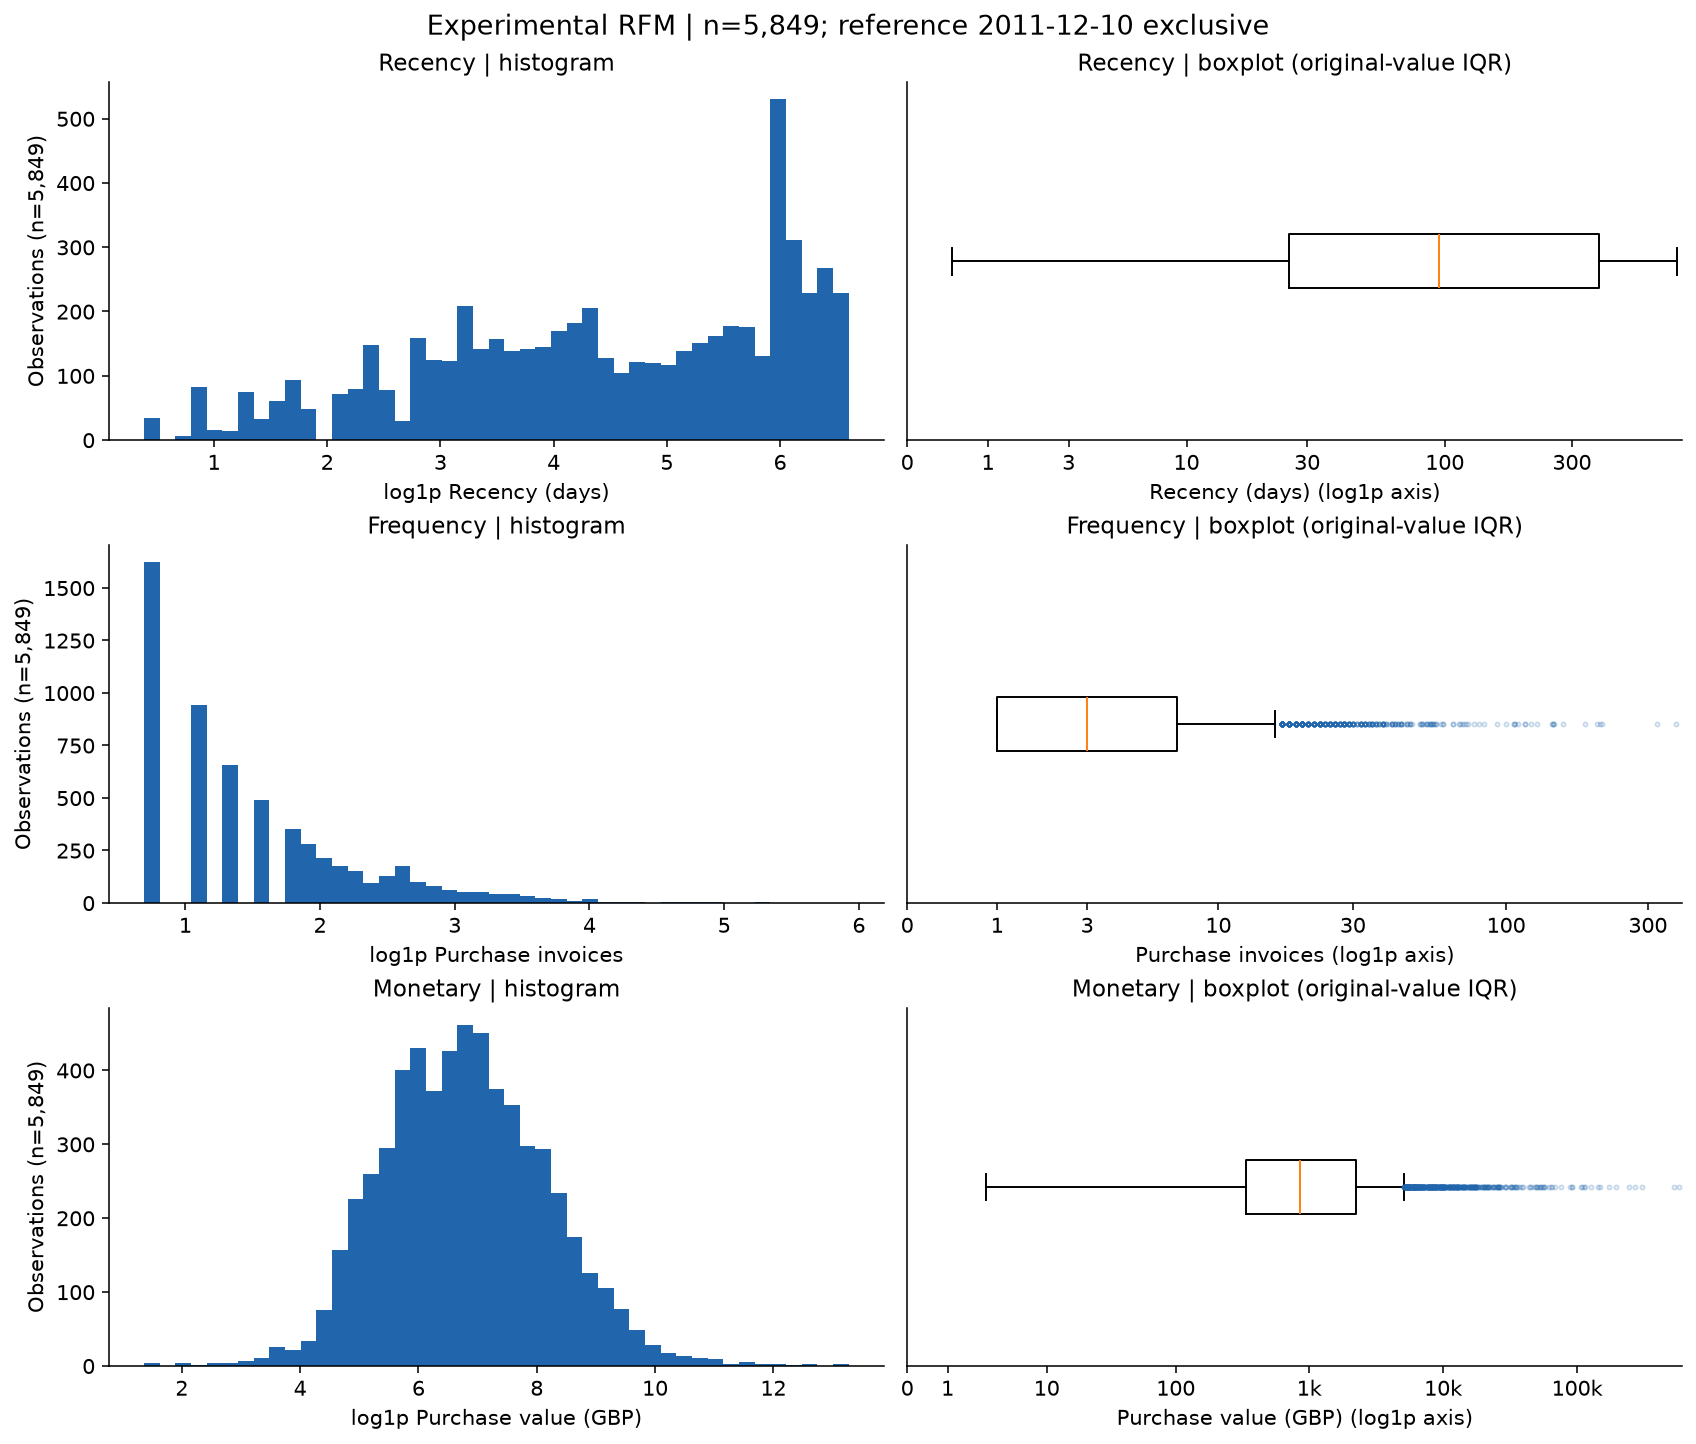

**Nhận xét:** Trung vị R=95.41 ngày; F=3 hóa đơn; M=851.88 GBP. R thiếu 0, F thiếu 0, M thiếu 0 khách; skew R/F/M=0.89/12.05/26.30.

**Ý nghĩa đối với phân cụm:** RFM thử nghiệm đủ dữ liệu cho khảo sát biến đổi; F/M có thang khác R nên cần cân nhắc trọng số và scaling.

**Giới hạn / bước tiếp theo:** R = reference − last invoice time; F = n_orders, M = total_purchase_value. Mốc tham chiếu 2011-12-10 loại trừ, không phải ngày hiện tại. Chưa chọn bộ biến mô hình chính thức.

In [42]:
show_figure(analysis, "rfm_experimental_distributions")

### Tham số biến đổi và dữ liệu dùng fit

Fit log1p + StandardScaler (ddof=0) trên toàn bộ khách của cùng snapshot thử nghiệm.
Bảng gốc, bảng log/scaled và tham số cùng một lần tính. Chưa chọn scaler tối ưu hoặc chạy mô hình.
Đọc cùng [ma trận tương quan](#eda-correlation) để cân nhắc trùng thông tin và trọng số biến.


In [43]:
with pd.option_context("display.float_format", "{:.17g}".format):
    display(tables["scaling_parameters"])
standardized = tables["rfm_transformed"].filter(like="z_log1p_")
display(pd.DataFrame({"mean": standardized.mean(), "std_ddof0": standardized.std(ddof=0)}))


,feature,mean_log1p,variance_log1p,scale_log1p,fit_customers
0,Recency,4.4481400833254972,2.4369449131437166,1.5610717194106478,5849
1,Frequency,1.5464103991400771,0.65242434538896343,0.80772789068408646,5849
2,Monetary,6.7976414213201002,1.9057127364300201,1.3804755472046653,5849


,mean,std_ddof0
z_log1p_Recency,1.895105e-16,1.0
z_log1p_Frequency,2.551102e-16,1.0
z_log1p_Monetary,-7.045902e-16,1.0


## 12. Kiểm tra, xuất kết quả và báo cáo

Kiểm tra khóa, công thức, tổng, gap, RFM, mọi cặp tương quan/n, scaling và SHA256 nguồn trước/sau.
Chỉ xuất 9 CSV cần bàn giao; các bảng mô tả/IQR/cực trị đã tính và hiển thị trong notebook,
không lưu thêm bản cache giữa các notebook.


In [44]:
print(validate_analysis(analysis))
output = export_tables(analysis)
from eda_report import write_report
report = write_report(analysis)
display(Markdown("Đã cập nhật [báo cáo EDA tổng hợp](../../reports/bao_cao_qua_trinh_eda.md)."))


Đạt: khóa, công thức, tổng, khoảng cách, mọi cặp tương quan/n, scaling và checksum nguồn.


Đã cập nhật [báo cáo EDA tổng hợp](../../reports/bao_cao_qua_trinh_eda.md).

## 13. Tổng hợp phát hiện và giới hạn

Các bảng/nhận xét có số liệu ở trên là bằng chứng cho chất lượng, hành vi, ngoại lệ và lựa chọn biến.
Cần Thuận/nhóm trưởng xác nhận chính sách dữ liệu, danh mục sản phẩm, hoàn trả, ngoại lệ và bộ biến/scaling.
Các vùng scatter chưa phải cụm chính thức. Chi tiết phát hiện và vấn đề cần xác nhận ở mục 12–13
của [báo cáo tổng hợp](../../reports/bao_cao_qua_trinh_eda.md).
Codex hỗ trợ tổ chức mã, diễn giải theo kết quả và rà soát tái lập; nhóm xác nhận nội dung trước khi nộp.
